# OpenTCAD: An Open-Source Process-to-Device-to-Circuit TCAD Framework, Demonstrated on a Light-Powered Microrobot Controller

```
Submission to IEEE SSCS Open-Source Ecosystem “Code-a-Chip” Travel Grant Awards at ISSCC'27
SPDX-License-Identifier: Apache-2.0
```

|Name|Affiliation|IEEE Member|SSCS Member|
|:--:|:----------:|:----------:|:----------:|
|Abhineet Agarwal|IIT Bombay, India|No|No|

## Abstract

I present OpenTCAD, an open-source Python framework that connects process simulation to drift–diffusion device simulation through one shared data object, and I show a path from a structure definition, through a mesh, optical generation and a DEVSIM solution, to a SPICE-ready compact model that open circuit-design flows can use. In this work I extended the framework with prescribed optical generation, explicit 2-D to physical current conversion, an ideal-diode compact model with maximum-power-point and SPICE export, and a correction to the electron/hole source signs in the core solver. I demonstrate these additions live, with a photon-budget bound and a dark negative control, and then use them in a case study: a light-powered microrobot controller inspired by Reynolds et al. (2022), in which the photovoltaic model supplies a SKY130 clock macro that is verified with DRC, LVS and parasitic extraction. Not achieved: full transistor-coupled controller startup remains unresolved, and the TCAD structures are conceptual and uncalibrated.

## Table of Contents

1. Introduction
2. Background
3. Requirements and Environment Setup
4. OpenTCAD in Action: from a Structure to a SPICE-Ready PV Model
5. Case Study: Powering a Microrobot Controller
6. Results
7. Discussion
8. Conclusion and Possible Future Improvements
9. References
10. Acknowledgements

## 1. Introduction

### 1.1 Motivation

Open circuit design now has open simulators, process design kits, layout tools and verification (ngspice, SKY130, Magic, Netgen). The device-physics step upstream of a compact model, however, still usually depends on commercial TCAD, which students and small labs cannot script, share or reproduce.

Light-powered microsystems depend on that step. In a microrobot such as the one of Reynolds et al. [1], the photovoltaic cell is the power supply: its current–voltage curve, area and series stacking set what the circuit can do, and the published controller draws under 1 µW. A reproducible, scriptable path from a device structure to a SPICE macromodel is therefore a reusable building block, useful well beyond this one robot.

### 1.2 Notebook Objective

In this notebook I:

- introduce OpenTCAD, its architecture and its current capabilities;
- run the optical and photovoltaic extension and validate it with a physical bound and a negative control;
- export the result to SPICE as a compact model;
- use it in a microrobot-controller case study whose clock macro has a layout with DRC, LVS and extracted-parasitic comparisons.

### 1.3 Notebook Organization

Section 2 gives the background and the OpenTCAD architecture. Section 3 lists the requirements and prepares the environment. Section 4 is the live OpenTCAD demonstration. Section 5 is the microrobot case study, and Section 6 collects the results. Sections 7 and 8 discuss limitations, conclude and list future work.

## 2. Background

### 2.1 TCAD in an Open Circuit-Design Flow

Technology CAD (TCAD) solves the coupled Poisson and carrier-continuity equations on a mesh to predict how a device behaves from its geometry, doping and materials. A circuit designer rarely needs the internal fields; they need terminal behaviour (I–V, C–V) in a form a circuit simulator can use. The path that matters is therefore:

structure → mesh → physics (here: optical generation and drift–diffusion) → terminal curves → compact model → SPICE.

### 2.2 OpenTCAD Architecture

Every layer boundary in OpenTCAD exchanges one object, `MeshField` (cell materials, nodal doping, contact tags and process history). Units are fixed throughout: µm, cm⁻³, K and eV. The status column reflects what is implemented in the repository.

| Layer | Module | Backend | Status |
|---|---|---|---|
| Structure and meshing | `opentcad.geometry` | Gmsh | implemented |
| Topography | `opentcad.process.topography` | ViennaLS | deposition, isotropic and directional etch, Deal–Grove oxidation; not run here (ViennaLS is not in this notebook's environment) |
| Doping | `opentcad.process.doping` | NumPy/SciPy | Gaussian and Pearson-IV implant, intrinsic Fickian anneal; not a calibrated process simulator |
| Process → device bridge | `opentcad.bridge` | none | implemented |
| Device physics | `opentcad.device` | DEVSIM | Poisson + drift–diffusion; Klaassen/Canali/Lombardi mobility; SRH, Auger and radiative recombination; Slotboom band-gap narrowing; Fermi–Dirac; I–V and C–V sweeps. Run live in Section 4. |
| Optics and PV (new in this work) | `opentcad.device.optical`, `.compact` | none | Beer–Lambert generation; ideal-diode compact model, maximum power point, SPICE export |
| Materials | YAML database with pydantic validation | none | implemented |
| Planned | concentration-dependent diffusion (FiPy), calibration against SKY130/IHP, NEGF | | not implemented |

The core never depends on an application: the microrobot code of Section 5 imports OpenTCAD, not the other way round. An independent Linux re-run of the repository test suite (at an earlier commit) passed 170 tests with 4 optional-tool skips (ngspice and Icarus Verilog). This folder bundles a focused subset, run with `python -m pytest -ra`.

### 2.3 The Microrobot that Motivates the Case Study

Reynolds et al. [1] demonstrated 100–250 µm robots powered by light, controlled by onboard CMOS electronics, that walk at more than 10 µm/s using platinum electrochemical actuators [2]. The publication discloses block-level behaviour (a relaxation-oscillator clock, a divider that produces eight phases, two separate photovoltaic groups for logic and actuators) but not schematics, device sizes or photovoltaic areas. My case study is therefore a functional re-implementation inspired by [1], not a reproduction: the original used X-FAB XT018 180 nm SOI, while I use the open SKY130 PDK. Later work from the Penn–Michigan groups [3, 4, 5] moved to electrokinetic propulsion and a much more capable onboard computer; I treat those as future work.

## 3. Requirements and Environment Setup

The notebook needs the OpenTCAD source and the application code in `examples/microrobot`. Inside the full project folder it uses that folder. Run on its own, the setup cell downloads a pinned commit of the OpenTCAD repository (github.com/abhineet-agarwal/opentcad) into `opentcad_source/` next to the notebook. The same cell installs what the notebook needs:

- Python packages. Any of NumPy, SciPy, DEVSIM 2.10.0, Gmsh 4.15.2, PyVista, Matplotlib, pydantic and PyYAML that are missing are installed with pip at the pinned versions. Packages that are already present are left alone.
- Linux system libraries. DEVSIM needs BLAS/LAPACK and Gmsh needs GLU. On Debian and Ubuntu the cell installs `libblas3 liblapack3 libopenblas0-pthread libglu1-mesa` with apt-get when it can (as root, or with passwordless sudo) and otherwise prints the command to run. It also points DEVSIM at the versioned library names before DEVSIM is first imported.

The first run needs network access for the download and the installs; later runs do not. The pinned versions were validated on Python 3.12.

Sections 5.9 and 5.10 rerun the clock transients and the layout, DRC, LVS and extraction flow with ngspice, Magic, Netgen and the SKY130A PDK. On Linux x86-64 the notebook installs all of them (conda through micromamba, and the PDK from GitHub release assets), which takes a few minutes; set `RERUN_EDA = False` in Section 5.9 to skip both sections. Nothing else needs a PDK or an external tool. The archived runs used Magic 8.3.546, Netgen 1.5.325 and SKY130A/open_pdks 1.0.535; the PDK version is the same here and the tools are the nearest conda versions.

Inside the full project folder, `python execute_notebooks.py .` re-executes this notebook and checks that no packaged input changed; the Python version and platform of the packaged run are in `execution_validation.json`. Google Colab has not been tested.

The next cell installs missing dependencies, finds or fetches the project source, sets up helper functions and prints the environment.


In [1]:
import os, sys, subprocess, shutil, ctypes, importlib.util, tarfile, tempfile, urllib.request
from importlib import metadata

# 1. Python packages: install only what is missing, at the pinned versions.
PINNED = {"numpy": "numpy==2.4.4", "scipy": "scipy==1.17.1", "devsim": "devsim==2.10.0",
          "gmsh": "gmsh==4.15.2", "pyvista": "pyvista==0.47.3", "matplotlib": "matplotlib==3.10.8",
          "pydantic": "pydantic==2.13.3", "yaml": "PyYAML==6.0.3"}

def run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)

missing = [pin for module, pin in PINNED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing with pip:", ", ".join(missing))
    pip = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing]
    result = run(pip)
    if result.returncode and "No module named pip" in result.stderr:
        run([sys.executable, "-m", "ensurepip", "--upgrade"])
        result = run(pip)
    if result.returncode:
        raise RuntimeError("pip install failed:\n" + result.stderr[-1500:])
    importlib.invalidate_caches()
else:
    print("Python packages: all present")

# 2. Linux system libraries: BLAS/LAPACK for DEVSIM, GLU for Gmsh.
if sys.platform.startswith("linux"):
    LIBRARIES = {"libopenblas.so.0": "libopenblas0-pthread", "liblapack.so.3": "liblapack3",
                 "libblas.so.3": "libblas3", "libGLU.so.1": "libglu1-mesa"}
    def present(library):
        try:
            ctypes.CDLL(library)
            return True
        except OSError:
            return False
    needed = sorted({package for library, package in LIBRARIES.items() if not present(library)})
    if needed:
        sudo = [] if os.geteuid() == 0 else ["sudo", "-n"]
        manual = "sudo apt-get install -y " + " ".join(needed)
        if shutil.which("apt-get") and (sudo == [] or shutil.which("sudo")):
            print("Installing system libraries:", " ".join(needed))
            run([*sudo, "apt-get", "update", "-qq"])
            if run([*sudo, "apt-get", "install", "-y", *needed]).returncode:
                print("Automatic install failed. Run:", manual)
        else:
            print("Install the system libraries with:", manual)
    # DEVSIM looks for unversioned BLAS/LAPACK names; Debian/Ubuntu ship versioned ones.
    # This must be set before devsim is first imported.
    os.environ.setdefault("DEVSIM_MATH_LIBS", "libopenblas.so.0:liblapack.so.3:libblas.so.3")

print("Versions:", ", ".join(f"{name} {metadata.version(name)}" for name in
      ("numpy", "scipy", "devsim", "gmsh", "pyvista", "matplotlib")))
from pathlib import Path
from uuid import uuid4
from io import BytesIO
import hashlib, html, json, re, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display

# 3. Project source: use this folder if it contains OpenTCAD, otherwise fetch a pinned commit from GitHub.
SOURCE_REPO = "abhineet-agarwal/opentcad"
SOURCE_COMMIT = "732e98f007d2370d5011c989edf2353810de6ab7"
SOURCE_PARTS = ("opentcad", "examples", "docs")
# Figure-derived and supplied measurement data of unverified licence stay out of the download.
DATA_DIR, DATA_KEEP = "examples/microrobot/data/", ("README.md", "reynolds2022_AUDIT.md", "reynolds2022_inventory.json")

def fetch_source(target):
    if shutil.which("git"):
        shutil.rmtree(target, ignore_errors=True)
        target.mkdir(parents=True)
        steps = (["init", "-q"], ["remote", "add", "origin", f"https://github.com/{SOURCE_REPO}.git"],
                 ["sparse-checkout", "set", "--no-cone", *[f"/{part}/" for part in SOURCE_PARTS], f"!/{DATA_DIR}*",
                  *[f"/{DATA_DIR}{name}" for name in DATA_KEEP]],
                 ["fetch", "-q", "--depth", "1", "--filter=blob:none", "origin", SOURCE_COMMIT],
                 ["checkout", "-q", "FETCH_HEAD"])
        if all(subprocess.run(["git", *step], cwd=target, capture_output=True).returncode == 0 for step in steps):
            return "git"
        shutil.rmtree(target, ignore_errors=True)
    url = f"https://codeload.github.com/{SOURCE_REPO}/tar.gz/{SOURCE_COMMIT}"
    with tempfile.TemporaryFile() as archive:
        with urllib.request.urlopen(url, timeout=120) as response:
            shutil.copyfileobj(response, archive)
        archive.seek(0)
        with tarfile.open(fileobj=archive, mode="r:gz") as tar:
            keep = []
            for member in tar.getmembers():
                member.name = member.name.split("/", 1)[1] if "/" in member.name else ""
                in_data = member.name.startswith(DATA_DIR) and member.name[len(DATA_DIR):] not in DATA_KEEP
                if member.name.split("/")[0] in SOURCE_PARTS and not in_data:
                    keep.append(member)
            tar.extractall(target, members=keep, filter="data")
    return "tarball"

ROOT = Path.cwd().resolve()
if not (ROOT / "opentcad/__init__.py").is_file():
    ROOT = ROOT / "opentcad_source"
    if not (ROOT / "opentcad/__init__.py").is_file():
        print("Fetching", SOURCE_REPO, "at", SOURCE_COMMIT[:7], "from GitHub")
        print("Fetched with", fetch_source(ROOT))
assert (ROOT / "opentcad/__init__.py").is_file(), "OpenTCAD source not found and the GitHub download failed"
sys.path.insert(0, str(ROOT))
APP = ROOT / "examples/microrobot"
ARCHIVE = APP / "results"
from examples.microrobot.tcad_demo import run
OUTPUT = APP / "local_runs" / ("submission_" + uuid4().hex[:12])

def read(name):
    return json.loads((ARCHIVE / name).read_text())
def table(headers, rows):
    text = '<table><thead><tr>' + ''.join('<th>'+html.escape(str(x))+'</th>' for x in headers) + '</tr></thead><tbody>'
    text += ''.join('<tr>'+''.join('<td>'+html.escape(str(x))+'</td>' for x in row)+'</tr>' for row in rows)
    display(HTML(text+'</tbody></table>'))
def details(title, obj):
    text = re.sub(r'/(?:Users|home)/[^/\s"\']+', '<USER_HOME>', json.dumps(obj, indent=2))   # archived records name the author's machine
    display(HTML('<details><summary>'+html.escape(title)+'</summary><pre>'+html.escape(text)+'</pre></details>'))
def picture(path, width=1100):
    display(Image(filename=str(path), width=width))
def showfig(fig):
    buffer = BytesIO(); fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue())); plt.close(fig)
def num(value, scale=1):
    return '—' if value is None else f'{value*scale:.6g}'
print("Python:", sys.version.split()[0])
print("Fresh output:", OUTPUT.relative_to(ROOT))
print("Section 4 runs OpenTCAD/DEVSIM live. Sections 5.9 and 5.10 rerun the clock transients and the layout flow. The rest of Section 5 reuses archived evidence.")

Python packages: all present
Versions: numpy 2.4.4, scipy 1.17.1, devsim 2.10.0, gmsh 4.15.2, pyvista 0.47.3, matplotlib 3.10.8


Python: 3.12.3
Fresh output: examples/microrobot/local_runs/submission_e2510c9e50d0
Section 4 runs OpenTCAD/DEVSIM live. Sections 5.9 and 5.10 rerun the clock transients and the layout flow. The rest of Section 5 reuses archived evidence.


## 4. OpenTCAD in Action: from a Structure to a SPICE-Ready PV Model

### 4.1 What this Work Added to the OpenTCAD Core

1. `BeerLambert`: prescribed monochromatic optical generation written onto a `MeshField` and used as the generation term in the DEVSIM continuity equations (`opentcad/device/optical.py`, [docs](https://github.com/abhineet-agarwal/opentcad/blob/732e98f007d2370d5011c989edf2353810de6ab7/docs/optical_generation.md)).
2. `current_from_2d` and `DeviceSolver.contact_current_A_per_cm`: conversion of a 2-D simulation to physical current, so a 2-D result is never read as amperes by accident.
3. `SingleDiodePV` and `fit_single_diode`: terminal fit, maximum-power point and SPICE subcircuit export (`opentcad/device/compact.py`, [docs](https://github.com/abhineet-agarwal/opentcad/blob/732e98f007d2370d5011c989edf2353810de6ab7/docs/photovoltaic_compact.md)).
4. A fix in the core solver. The electron and hole recombination/generation sources now have opposite signs and the hole time-charge sign is corrected, which restores terminal-current conservation. Earlier results with active recombination change; see `CHANGELOG.md`.
5. Regression tests and two small examples (`examples/07_photovoltaic.py`, `examples/08_pv_compact.py`).

### 4.2 Live Drift–Diffusion Solve of an Illuminated Silicon Cell

I build a generic 3 µm silicon diode (p-type 10¹⁶ cm⁻³ body, 0.3 µm n⁺ 10¹⁸ cm⁻³ layer) with the `Structure` DSL, mesh it with Gmsh and solve it with DEVSIM in the dark and at 1000 W/m², 660 nm. The absorption coefficient (3000 cm⁻¹), the reflectance (0.3) and the 20 µm out-of-plane depth are chosen values, not fits. If the solver cannot start in your environment, the next cell falls back to the archived curves for the same kind of structure and says so.

In [2]:
import contextlib, io, time
from opentcad.device.optical import BeerLambert, current_from_2d
from opentcad.device.compact import fit_single_diode
from opentcad.device.solver import DeviceSolver
from opentcad.geometry.formats import Material
from opentcad.geometry.structure import Structure
from opentcad.materials.database import load_material

DEPTH_UM, THICK_UM, N_UM, MESH_UM = 20.0, 3.0, 0.3, 0.16      # chosen geometry
WAVELENGTH_NM, ALPHA_CM, REFLECTANCE = 660.0, 3000.0, 0.3      # chosen optical parameters
V_MAX = 0.55                                                   # PV operating range
Q_C = 1.602176634e-19

@contextlib.contextmanager
def quiet():
    """DEVSIM prints solver iterations; silence both Python-level and C-level output."""
    sys.stdout.flush(); sys.stderr.flush()
    saved = os.dup(1), os.dup(2); null = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(null, 1); os.dup2(null, 2)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        os.dup2(saved[0], 1); os.dup2(saved[1], 2)
        for fd in (*saved, null): os.close(fd)

def solve_cell(devsim, irradiance_W_m2):
    mf = (Structure(width_um=1, name="generic_pv")
          .add_substrate("p", THICK_UM - N_UM, Material.SI, doping_Na=1e16)
          .add_layer("n", N_UM, Material.SI, doping_Nd=1e18)
          .add_contact("p", 0, 1, "p", surface="bottom")
          .add_contact("n", 0, 1, "n", surface="top")
          .to_meshfield(mesh_size_um=MESH_UM))
    optics = BeerLambert(WAVELENGTH_NM, irradiance_W_m2, ALPHA_CM, reflectance=REFLECTANCE)
    optics.apply(mf, surface_y_um=THICK_UM)
    solver = DeviceSolver(mf, {"Silicon": load_material("Si")})
    try:
        v, i = solver.iv_sweep("p", "n", 0, V_MAX, 0.025)
    finally:
        devsim.delete_device(device=solver._device_name)
    return np.array(v), -current_from_2d(np.array(i), depth_um=DEPTH_UM), optics, mf.n_points

AREA_UM2 = 1.0 * DEPTH_UM
live_error, started = None, time.time()
try:
    with quiet():
        import devsim
        runs = {E: solve_cell(devsim, E) for E in (0.0, 1000.0)}
    SOURCE = "live OpenTCAD/DEVSIM solve"
    (v0, i0, _, _), (v1, i1, optics, nodes) = runs[0.0], runs[1000.0]
    bound_A = Q_C * optics.absorbed_pairs_cm2_s(THICK_UM) * (AREA_UM2 * 1e-8)
except Exception as error:                                     # native solver unavailable
    live_error = f"{type(error).__name__}: {error}"
    archived = read("pv.json")
    SOURCE = "ARCHIVED curves (live solve unavailable)"
    def curve(key):
        d = archived[key]; v = np.array(d["voltage_V"]); i = np.array(d["delivered_A_per_um2"]) * AREA_UM2
        keep = v <= V_MAX + 1e-9
        return v[keep], i[keep]
    (v0, i0), (v1, i1) = curve("dark"), curve("light")
    bound_A = archived["light"]["absorbed_photon_limit_A_per_um2"] * AREA_UM2
    nodes = archived["light"]["nodes"]

print("Source:", SOURCE, f"({time.time() - started:.1f} s)")
if live_error:
    print("Live solve unavailable:", live_error[:200], "| see SETUP.md for the native libraries.")
print(f"Mesh nodes: {nodes} | physical area assumed: 1 µm × {DEPTH_UM:g} µm = {AREA_UM2:g} µm²")

Source: live OpenTCAD/DEVSIM solve (1.1 s)
Mesh nodes: 233 | physical area assumed: 1 µm × 20 µm = 20 µm²


### 4.3 Physical Checks, then the SPICE-Ready Compact Model

I check the curves in two ways before using them. The delivered short-circuit current must not exceed the absorbed-photon current: a collected fraction above 1 would point to a source or sign error, the kind of defect fixed in this work. And the cell must deliver essentially no current in the dark at zero bias, which serves as a negative control.

I then fit a three-parameter ideal-diode model to the TCAD data and compare the two on the quantities a circuit designer uses: short-circuit current, open-circuit voltage and maximum power. The fit covers 0 to 0.55 V, the operating range; above that, high-injection effects that an ideal diode does not model dominate. Finally the model is exported as a SPICE subcircuit.

Quantity,TCAD,Compact model,Model − TCAD
Short-circuit current (nA),2.74161,2.68741,-1.98 %
Open-circuit voltage (V),0.461028,0.464211,+0.69 %
Maximum power (nW),0.974835,0.98815,+1.37 %
Voltage at maximum power (V),0.4,0.392052,-1.99 %


Check,Value,Pass
Absorbed-photon bound (nA),4.42258,
Collected fraction Isc / bound (must be ≤ 1),0.620,yes
Dark current at 0 V relative to Isc,5.59e-20,yes
Fit RMS / maximum current error (nA),0.085 / 0.410,
Fitted ideality (per cell) / I0 (A) / Iph (nA),1.005 / 4.64e-17 / 2.6874,


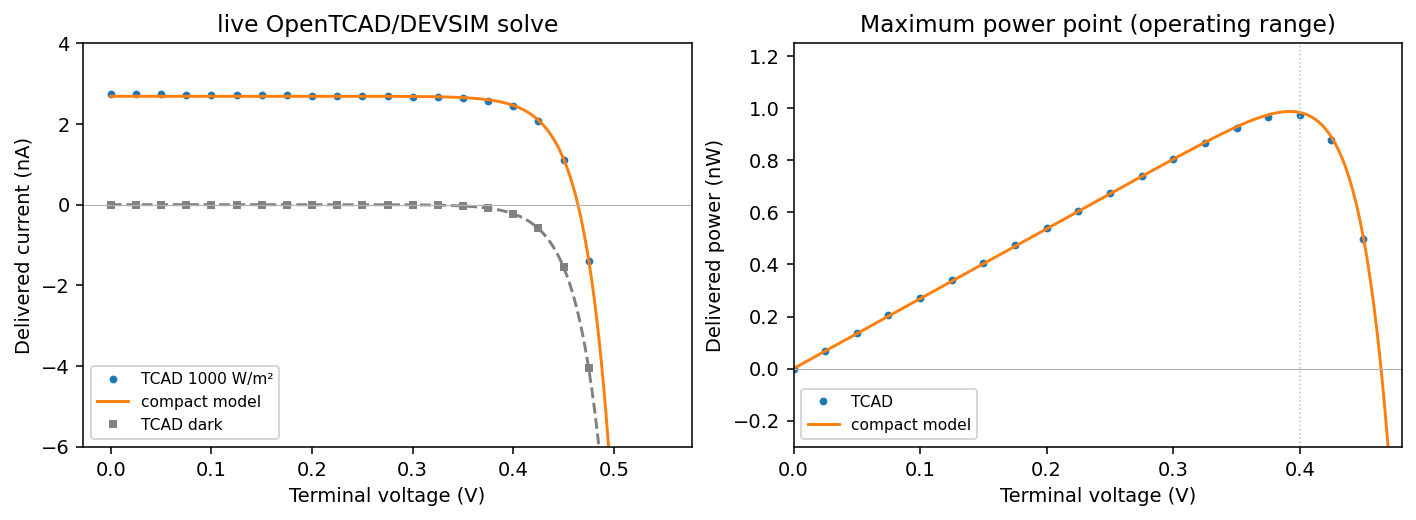

SPICE subcircuit exported by OpenTCAD (usable in ngspice):

* Terminal fit at 300 K; no charge/Rs/shunt model
.subckt opentcad_pv p n params: illumination=1000 area_scale=1
Iphoto n p DC {2.68740634757e-09*illumination/1000*area_scale}
Dpv p n opentcad_pv_diode area={area_scale}
.model opentcad_pv_diode D(IS=4.6362879692e-17 N=1.0045400183 TNOM=26.85 EG=0 XTI=0)
.ends opentcad_pv



In [3]:
isc = float(i1[0]); dark_at_0V = float(i0[0])
sign_change = np.where(np.diff(np.sign(i1)) != 0)[0]
k = sign_change[0]
voc_tcad = float(np.interp(0.0, [i1[k + 1], i1[k]], [v1[k + 1], v1[k]]))
power = v1 * i1; kmax = int(np.argmax(power))
pmax_tcad, vmp_tcad = float(power[kmax]), float(v1[kmax])
collection = isc / bound_A

v_fit = np.r_[v0, v1]; i_fit = np.r_[i0, i1]
light = np.r_[np.zeros_like(v0), np.full_like(v1, 1000.0)]
model, diag = fit_single_diode(v_fit, i_fit, light, uncertainty_A=np.maximum(1e-3 * np.abs(i_fit), 1e-13))
vmp_m, imp_m, pmax_m = model.maximum_power_point(1000.0)
isc_m, voc_m = float(model.current_A(0.0, 1000.0)), float(model.open_circuit_V(1000.0))

def rel(a, b): return f"{100 * (a - b) / b:+.2f} %"
table(["Quantity", "TCAD", "Compact model", "Model − TCAD"], [
    ["Short-circuit current (nA)", num(isc, 1e9), num(isc_m, 1e9), rel(isc_m, isc)],
    ["Open-circuit voltage (V)", num(voc_tcad), num(voc_m), rel(voc_m, voc_tcad)],
    ["Maximum power (nW)", num(pmax_tcad, 1e9), num(pmax_m, 1e9), rel(pmax_m, pmax_tcad)],
    ["Voltage at maximum power (V)", num(vmp_tcad), num(vmp_m), rel(vmp_m, vmp_tcad)],
])
table(["Check", "Value", "Pass"], [
    ["Absorbed-photon bound (nA)", num(bound_A, 1e9), ""],
    ["Collected fraction Isc / bound (must be ≤ 1)", f"{collection:.3f}", "yes" if 0 < collection <= 1 else "NO"],
    ["Dark current at 0 V relative to Isc", f"{abs(dark_at_0V) / isc:.2e}", "yes" if abs(dark_at_0V) < 1e-3 * isc else "NO"],
    ["Fit RMS / maximum current error (nA)", f"{diag['rms_current_error_A']*1e9:.3f} / {diag['maximum_current_error_A']*1e9:.3f}", ""],
    ["Fitted ideality (per cell) / I0 (A) / Iph (nA)", f"{model.ideality:.3f} / {model.saturation_A:.3g} / {model.photocurrent_A*1e9:.4f}", ""],
])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
vs = np.linspace(0, V_MAX, 200)
ax[0].plot(v1, i1 * 1e9, "o", ms=3, label="TCAD 1000 W/m²"); ax[0].plot(vs, model.current_A(vs, 1000.0) * 1e9, "-", label="compact model")
ax[0].plot(v0, i0 * 1e9, "s", ms=3, color="0.5", label="TCAD dark"); ax[0].plot(vs, model.current_A(vs, 0.0) * 1e9, "--", color="0.5")
ax[0].axhline(0, color="0.7", lw=0.6); ax[0].set(xlabel="Terminal voltage (V)", ylabel="Delivered current (nA)", ylim=(-6, 4), title=SOURCE)
ax[0].legend(fontsize=8)
ax[1].plot(v1, power * 1e9, "o", ms=3, label="TCAD"); ax[1].plot(vs, vs * model.current_A(vs, 1000.0) * 1e9, "-", label="compact model")
ax[1].axvline(vmp_tcad, color="0.75", lw=0.8, ls=":"); ax[1].axhline(0, color="0.7", lw=0.6)
ax[1].set(xlabel="Terminal voltage (V)", ylabel="Delivered power (nW)", title="Maximum power point (operating range)",
          xlim=(0, voc_tcad + 0.02), ylim=(-0.3, 1.25)); ax[1].legend(fontsize=8, loc="lower left")
showfig(fig)

print("SPICE subcircuit exported by OpenTCAD (usable in ngspice):\n")
print(model.spice_subcircuit("opentcad_pv"))

### 4.4 Scope of this Section

This section runs the OpenTCAD pipeline from a structure definition through mesh, optical generation and drift–diffusion solution to a circuit-ready macromodel, with a physical bound and a negative control, in a few seconds on a laptop.

It does not show a calibrated device. Doping is analytically prescribed, absorption and reflectance are chosen, there is no surface recombination, and the ideal-diode model has no series or shunt resistance. A real device would give different numbers.

The process-simulation half of the pipeline (topography, implant, anneal) is not run here. It exists in the repository (`examples/04` to `06`) with its own tests, but ViennaLS is not part of this notebook's pinned environment.

## 5. Case Study: Powering a Microrobot Controller

The photovoltaic output of Section 4 feeds the case study. The chain, from light to bending, is:

archived drift–diffusion dark/light tables → characterized schematic clock and first divider flip-flop → behavioral divider/reset and finite-resistance drivers → nonlinear electrochemistry with a finite Pt return → assumed bending mechanics.

Reynolds et al. (2022) [1] is the starting point, Miskin et al. (2020) [2] supplies supporting actuator physics, and Lassiter et al. (2025) [3] is future work. See `references.md` for the evidence and `data/README.md` for extraction.

Full transistor-coupled controller startup failed and remains unresolved, and the reduced-system runs below do not change that. PV and process parameters are conceptual, mechanics are assumed, walking and contact forces are absent, and physical verification covers the clock macro, not a complete controller. Each subsection says whether its evidence is fresh (computed when the notebook runs) or archived (from earlier runs, shown but not regenerated). No raw SPICE transient, local reference PDF or supplied measurement CSV is redistributed.

### 5.1 The Compact Clock Layout

This picture is rendered from the flat Magic paint, excluding checkpaint. It shows the compact clock macro, its bias circuitry and routing. The paint bounding box is 464.615 × 84.465 µm, about 39,243.706 µm². These are paint extents, not an accepted robot footprint. The comparison baseline spans 615.615 × 84.465 µm. Native and GDS-roundtrip DRC/LVS evidence and extracted RC follow later.

This is not a full controller layout. The divider, supervisor, transistor drivers, PV isolation, actuator geometry and footprint closure are outside this macro.

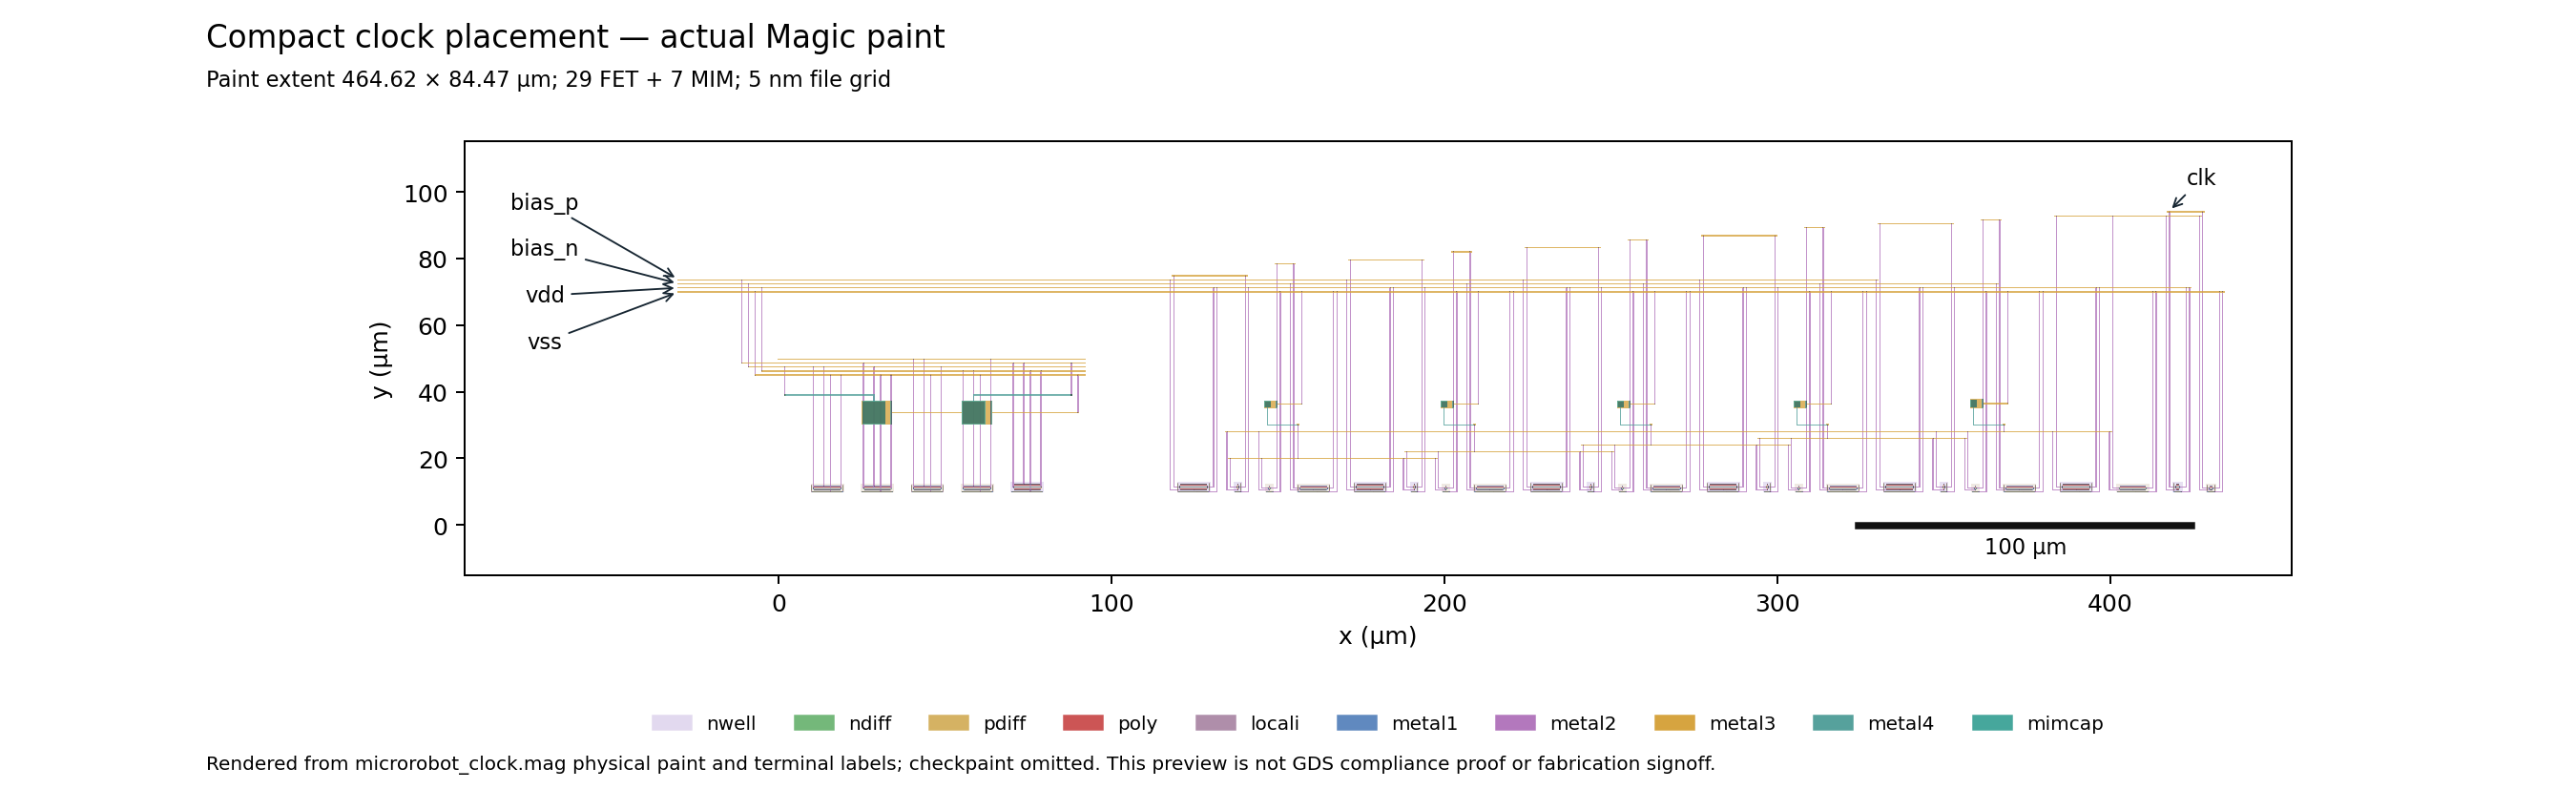

Paint geometry,Width µm,Height µm,Bounding area µm²
stage_local,615.615,84.465,51997.9
compact_x,464.615,84.465,39243.7


In [4]:
compact = read("clock_compact_placement/metrics.json")
picture(ARCHIVE / "clock_compact_placement/prototype_layout.png")
table(["Paint geometry", "Width µm", "Height µm", "Bounding area µm²"],
      [(name, num(v["width_um"]), num(v["height_um"]), num(v["bounding_box_area_um2"])) for name,v in compact["area"].items()])
details("Complete compact placement, geometry and extraction record", compact)


### 5.2 Device Input: Drift–Diffusion Curves and the Calibration Gap

The PV calculation is a conceptual 3 µm Si junction at 300 K with 660 nm Beer–Lambert illumination, abrupt assumed doping and ideal ohmic contacts. It implies no foundry PV process, measured-device fit, sidewall calibration or broadband optical calibration. The source arrays are OpenTCAD/DEVSIM drift–diffusion outputs, not the empirical terminal fit.

The 6 s system uses four logic cells and two series cells in each actuator half, each at an assumed 1080 µm²: eight cells, 8640 µm² in total. Equal current density under area scaling, electrical isolation and linear photocurrent superposition are assumptions. The original paper uses a different supply topology and cell allocation.

Published approximate anchors are about 0.3 A/W and 0.6 V per cell; the conceptual drift–diffusion result is near 0.1355 A/W and 0.461 V. Separate observed-trace summaries and a fixed-structure reflection-only feasibility study are included below as archived comparisons. They are not a calibration of this PV.

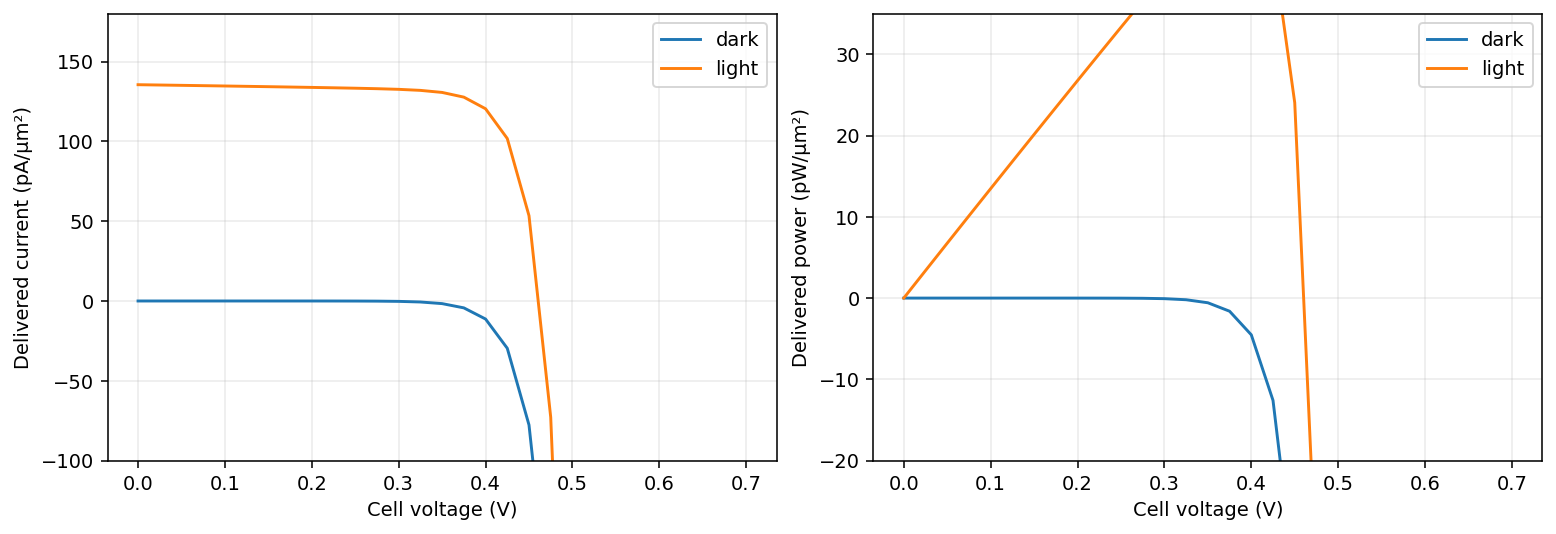

Quantity,Conceptual DD,Published approximate anchor,Interpretation
One-sun responsivity A/W,0.135497,~0.3,Uncalibrated
Cell Voc V,0.460582,~0.6,Uncalibrated
Cell Isc pA/µm²,135.497,Not substituted,Actual DD input
Medium/fine Isc relative change,0.00365605,Not measurement agreement,Mesh comparison


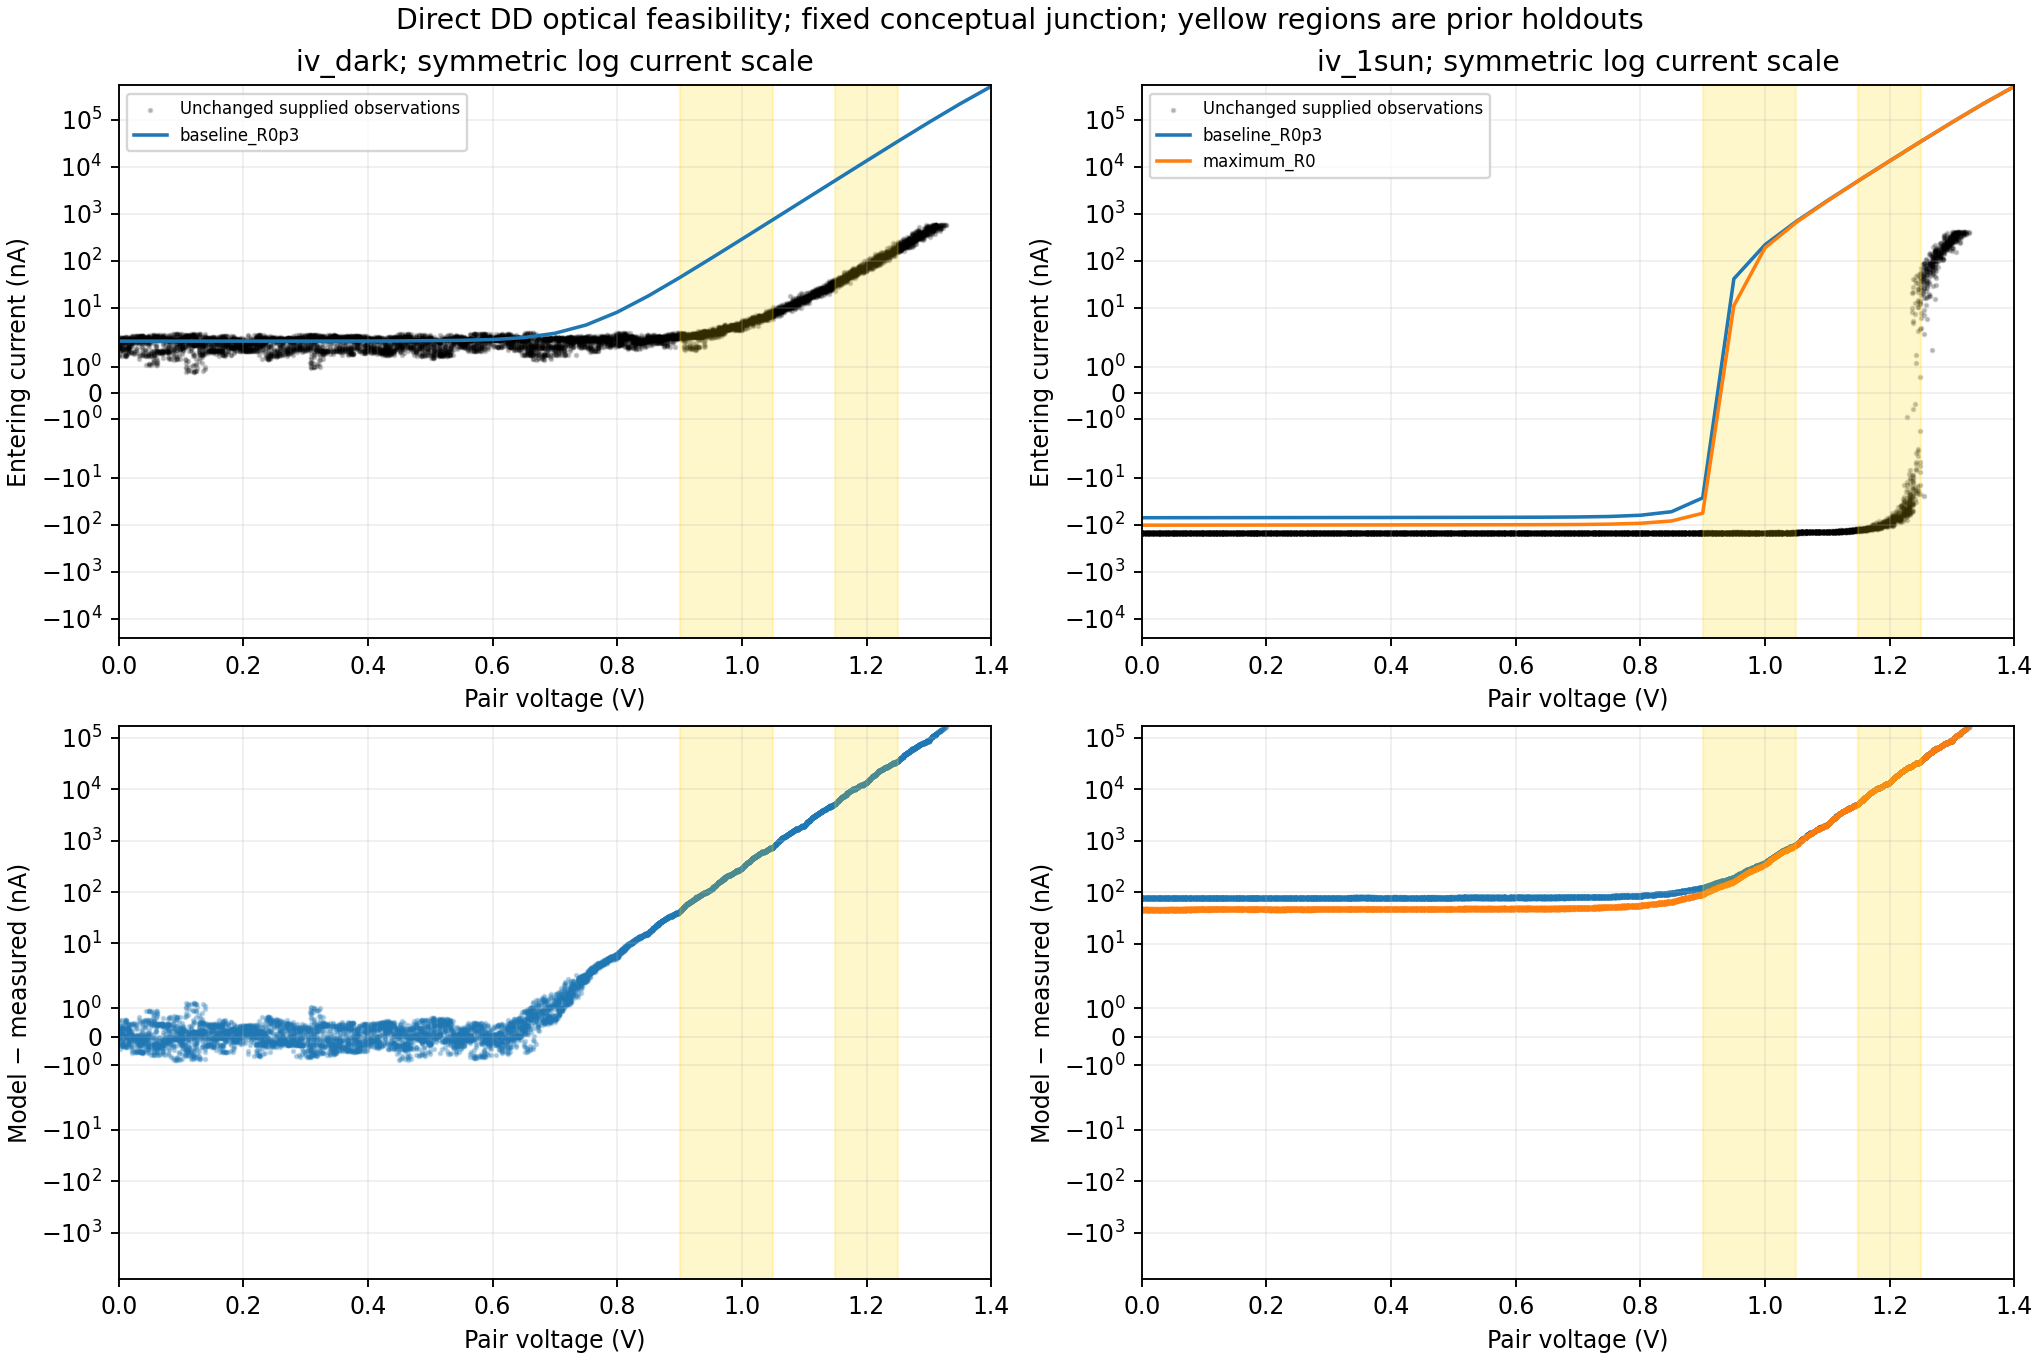

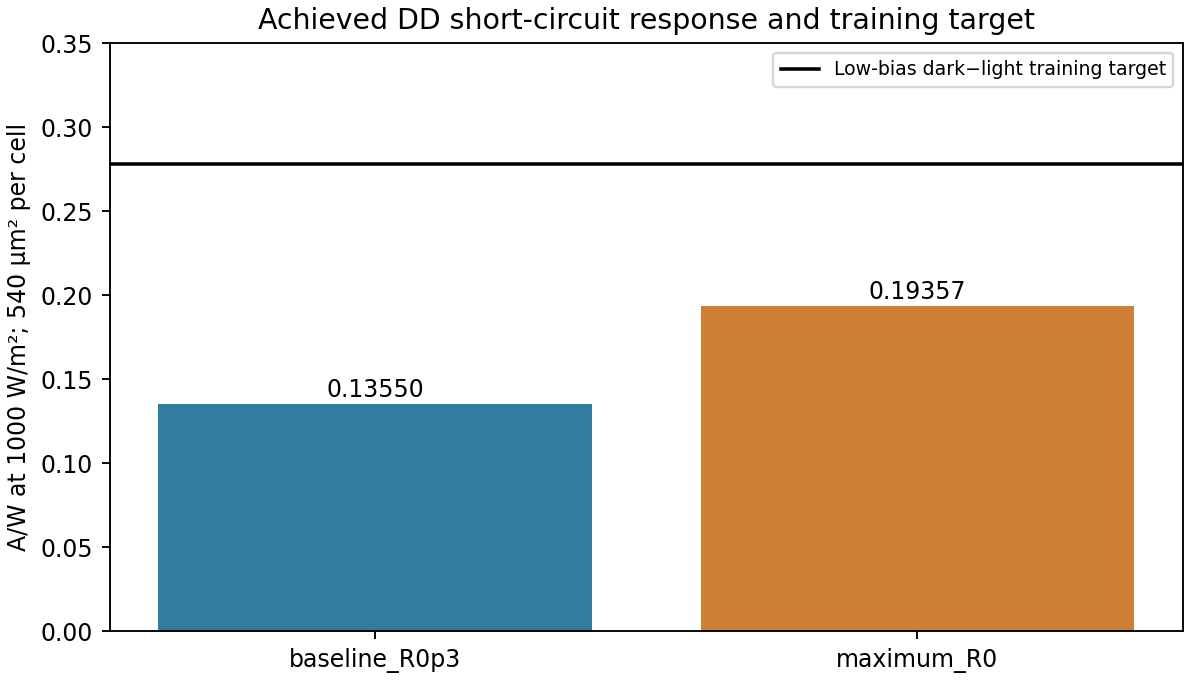

Reflection-only feasibility quantity,Archived value
target_A,1.5006011914395906e-07
maximum_R0_A,1.0445227875063854e-07
bracketed,False
linearized_required_effective_reflectance,-0.436638060354827
required_input_multiplier_at_R0,1.436638060354827
relative_shortfall_at_R0,0.303930455696673
inference,Linearized photocurrent-throughput relation used only to propose a bounded third DD curve; not a fitted process parameter


In [5]:
pv = read("pv.json")
fig, axes = plt.subplots(1,2,figsize=(11,3.7),layout="constrained")
for label in ("dark","light"):
    v=np.asarray(pv[label]["voltage_V"]); i=np.asarray(pv[label]["delivered_A_per_um2"])
    axes[0].plot(v,i*1e12,label=label); axes[1].plot(v,v*i*1e12,label=label)
axes[0].set(xlabel="Cell voltage (V)",ylabel="Delivered current (pA/µm²)",ylim=(-100,180))
axes[1].set(xlabel="Cell voltage (V)",ylabel="Delivered power (pW/µm²)",ylim=(-20,35))
for ax in axes: ax.legend(); ax.grid(alpha=.25)
showfig(fig)
table(["Quantity","Conceptual DD","Published approximate anchor","Interpretation"], [
    ["One-sun responsivity A/W",num(pv["light"]["responsivity_A_W"]),"~0.3","Uncalibrated"],
    ["Cell Voc V",num(pv["light"]["voc_V"]),"~0.6","Uncalibrated"],
    ["Cell Isc pA/µm²",num(pv["light"]["isc_A_per_um2"],1e12),"Not substituted","Actual DD input"],
    ["Medium/fine Isc relative change",num(abs(pv["medium_mesh"]["isc_A_per_um2"]/pv["light"]["isc_A_per_um2"]-1)),"Not measurement agreement","Mesh comparison"]])
details("Complete archived DD dark/light/mesh/lifetime/half-light arrays and terminal audits",pv)
calibration=read("pv_calibration_feasibility/metrics.json")
picture(ARCHIVE/"pv_calibration_feasibility/dd_comparison.png",1000)
picture(ARCHIVE/"pv_calibration_feasibility/throughput_feasibility.png",1000)
table(["Reflection-only feasibility quantity","Archived value"],list(calibration["feasibility"].items()))
details("Complete calibration-feasibility and observed acquisition-order summaries",calibration)


### 5.3 End-to-End Mixed-Abstraction Execution

The next cell runs exactly three inexpensive Python model cases: 6 s nominal at 1 ms, 6 s refinement at 0.5 ms, and a 6 s all-dark negative control. Illumination is off before 0.05 s, on until 3 s, dark during 3–3.4 s, then restored. Clock frequency and current follow the bounded schematic TT lookup; the extracted-clock evidence is separate. The remaining divider and reset behavior and the finite 100 MΩ drivers are behavioral. Local double-layer, adsorption and faradaic branches and the finite Pt return feed back to the finite PV supplies.

The nominal and fine runs must stay finite and reach 6 s. The notebook asserts startup, shutdown, recovery, quarter-cycle phase, bounded adsorption coverage, PV and clock domains, electrolyte KCL and the energy residual. A 5% threshold applies to the reported principal timestep differences. This verifies the stated reduced model, not the unresolved transistor implementation.

In [6]:
report=run(OUTPUT,dt_s=0.001,duration_s=6.0)
assert report["all_gates_pass"],report["gates"]
table(["Acceptance gate","Pass"],report["gates"].items())
table(["Case","Rows","Start s","Actual stop s","Requested stop s","Complete","Finite"],
      [(k,v["rows"],v["start_s"],v["actual_stop_s"],v["requested_stop_s"],v["complete"],v["finite"]) for k,v in report["completion"].items()])
metrics=["mean_gait_Hz","startup_enable_s","steady_logic_V","steady_actuator_span_V","bending_peak_to_peak_rad","measured_phase_B_lag_cycles","electrical_energy_balance_relative_residual","electrolyte_KCL_peak_A"]
table(["Metric (units in name)","Nominal 1 ms","Fine 0.5 ms"],[(k,num(report["nominal"][k]),num(report["fine"][k])) for k in metrics])
table(["Principal refinement metric","Relative change","Threshold"],[(k,num(v),"0.05") for k,v in report["timestep_relative_changes"].items()])
table(["All-dark quantity","Maximum absolute value"],report["all_dark_max_abs"].items())
details("Complete fresh nominal/fine/dark summary, every metric and acceptance gate",report)


Acceptance gate,Pass
finite,True
startup,True
shutdown,True
recovery,True
phase_quarter_cycle,True
predicted_bend_nonzero,True
bounded_coverage,True
PV_domain,True
active_clock_envelope,True
KCL,True


Case,Rows,Start s,Actual stop s,Requested stop s,Complete,Finite
nominal,6001,0.0,6.0,6.0,True,True
fine,12001,0.0,6.0,6.0,True,True
all_dark,6001,0.0,6.0,6.0,True,True


Metric (units in name),Nominal 1 ms,Fine 0.5 ms
mean_gait_Hz,1.96418,1.96418
startup_enable_s,0.051,0.051
steady_logic_V,1.81668,1.81668
steady_actuator_span_V,1.84132,1.84132
bending_peak_to_peak_rad,0.97743,0.977498
measured_phase_B_lag_cycles,0.25076,0.250105
electrical_energy_balance_relative_residual,0.00143794,0.000827316
electrolyte_KCL_peak_A,2.75038e-23,2.06795e-23


Principal refinement metric,Relative change,Threshold
mean_gait_Hz,0,0.05
bending_peak_to_peak_rad,6.98522e-05,0.05
bias_mean_W,3.50361e-15,0.05
driver_J_per_cycle,0.0157852,0.05
recovered_bending_peak_to_peak_rad,0.000157886,0.05


All-dark quantity,Maximum absolute value
logic_V,0.0
positive_V,0.0
negative_magnitude_V,0.0
phase_cycles,0.0
drive_A_V,0.0
drive_B_V,0.0
curvature_A_m_inv,0.0
curvature_B_m_inv,0.0
storage_J,0.0
enabled,0.0


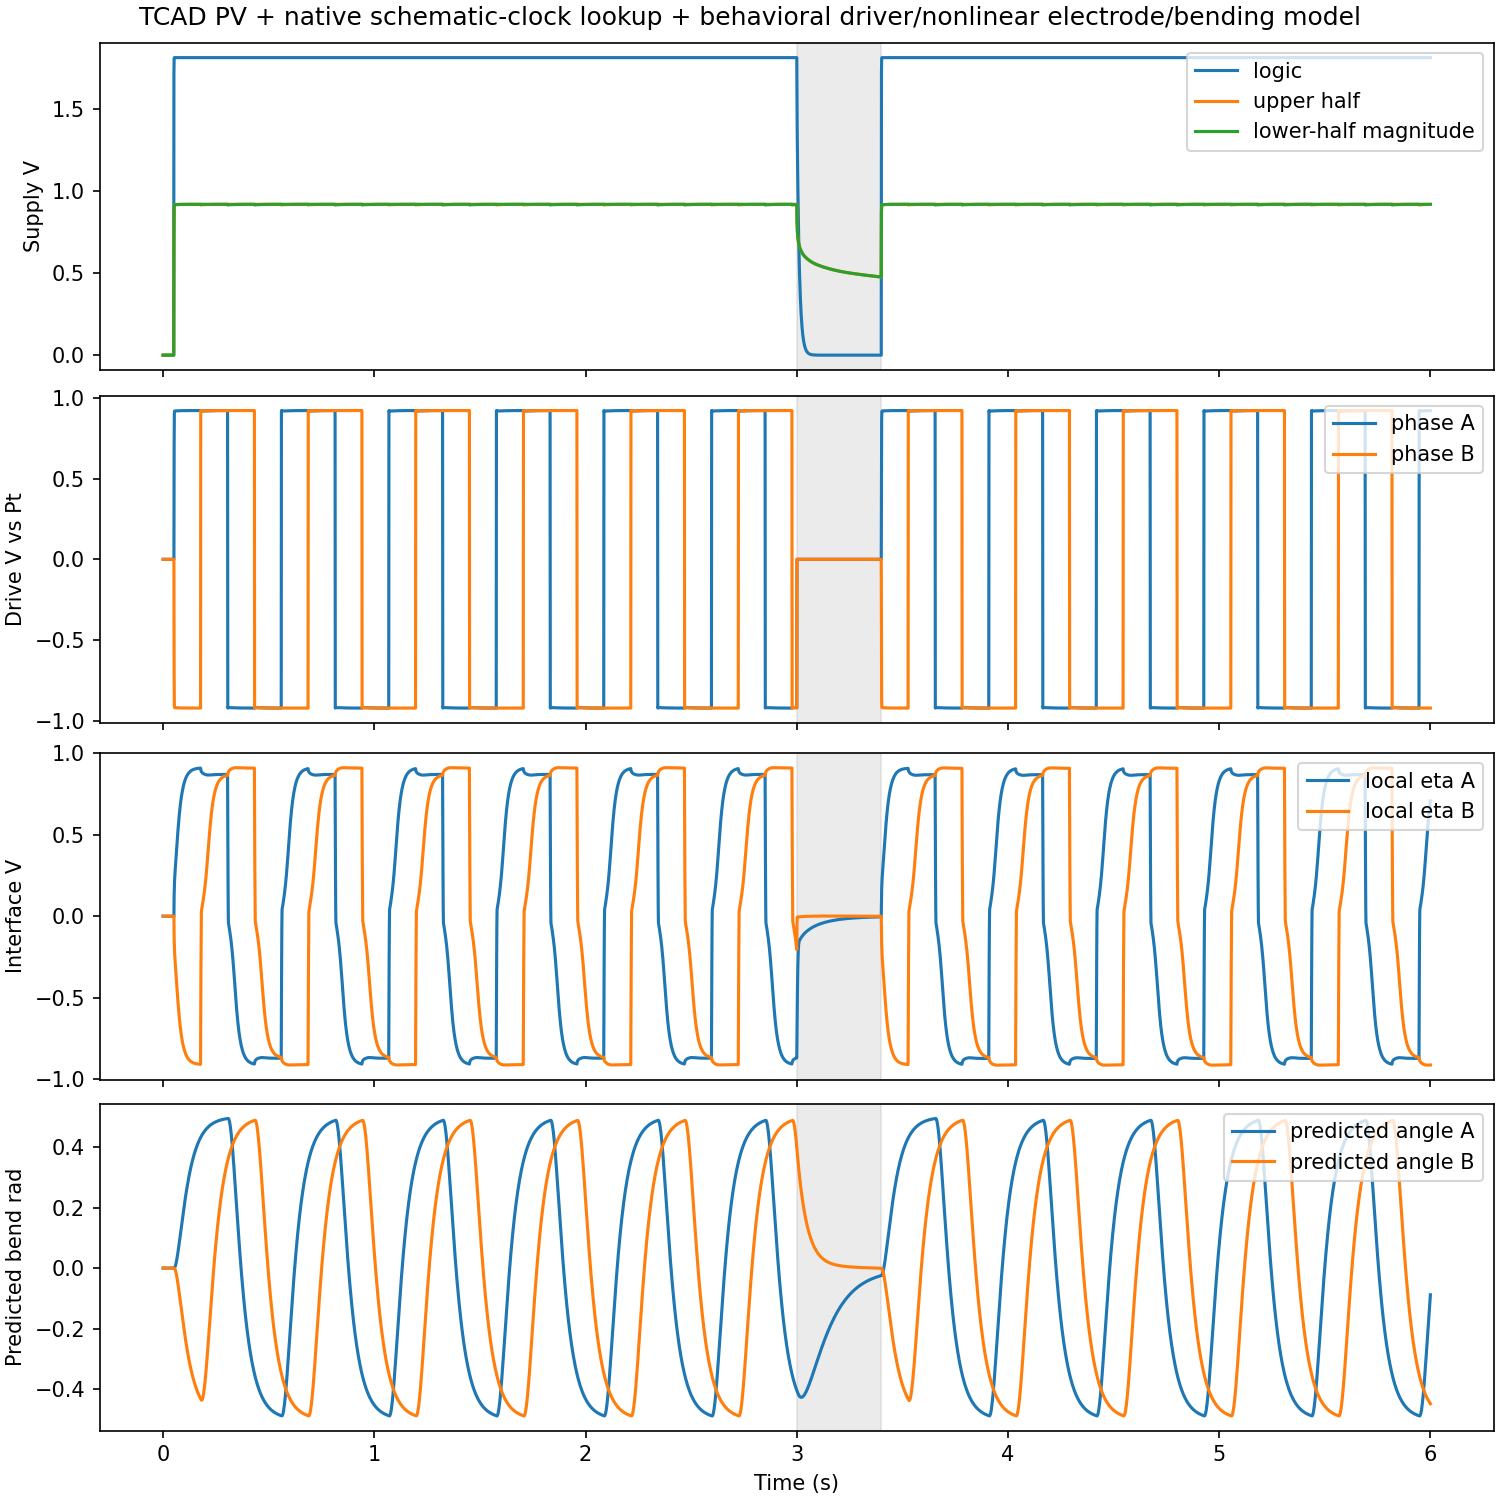

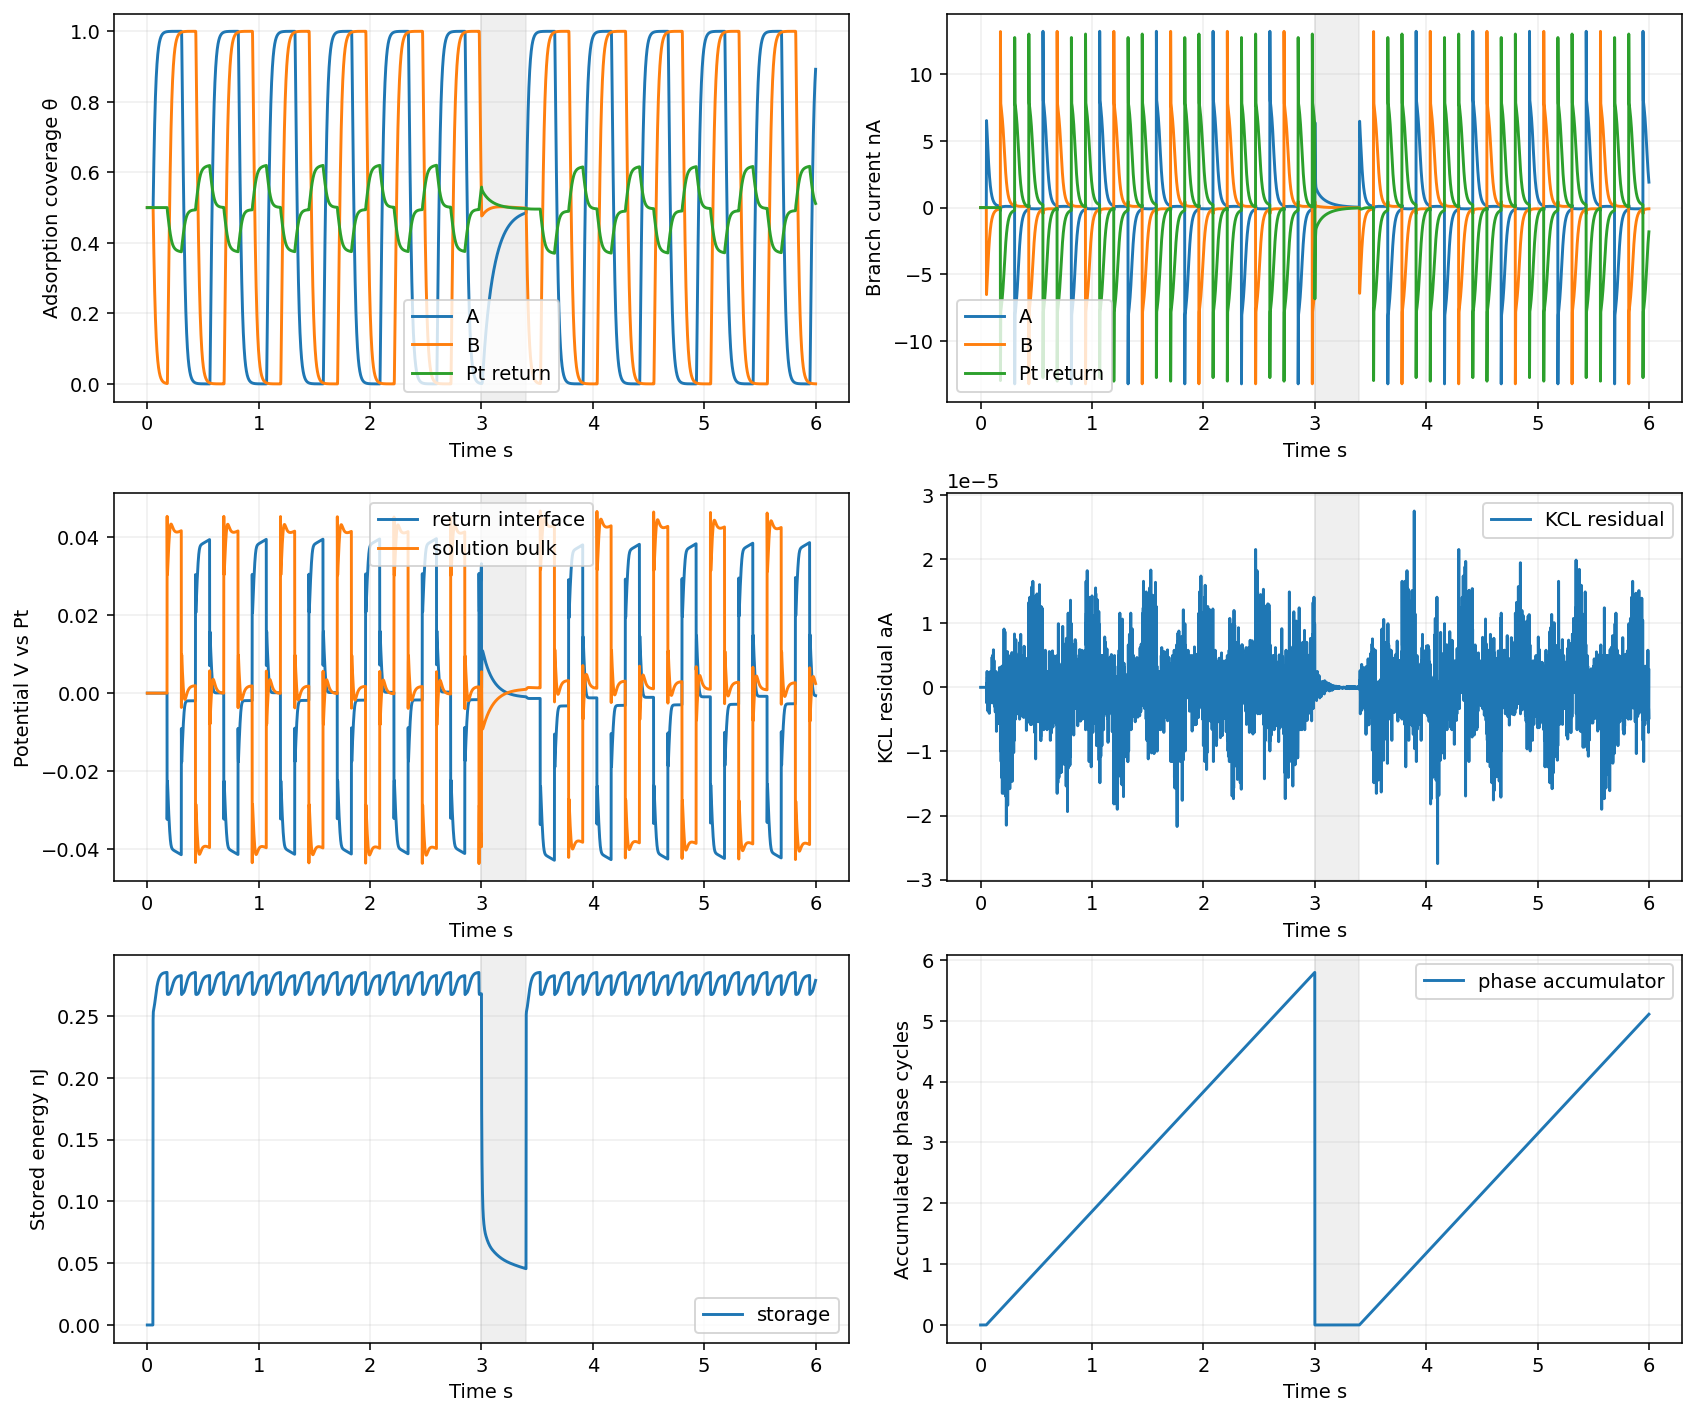

Nominal enable rises s: [0.051000000000000004, 3.4010000000000002] ; falls s: [3.001]


In [7]:
picture(OUTPUT/"system.png")
wave=np.genfromtxt(OUTPUT/"waveforms.csv.gz",delimiter=",",names=True)
t=wave["time_s"]
fig,axes=plt.subplots(3,2,figsize=(12,10),layout="constrained")
for leg in ("A","B"):
    axes[0,0].plot(t,wave[f"theta_{leg}"],label=leg)
    axes[0,1].plot(t,wave[f"current_{leg}_A"]*1e9,label=leg)
axes[0,0].plot(t,wave["theta_return"],label="Pt return")
axes[0,1].plot(t,wave["current_return_A"]*1e9,label="Pt return")
axes[1,0].plot(t,wave["eta_return_V"],label="return interface")
axes[1,0].plot(t,wave["electrolyte_bulk_V"],label="solution bulk")
axes[1,1].plot(t,wave["electrolyte_KCL_A"]*1e18,label="KCL residual")
axes[2,0].plot(t,wave["storage_J"]*1e9,label="storage")
axes[2,1].plot(t,wave["phase_cycles"],label="phase accumulator")
for ax,ylabel in zip(axes.flat,["Adsorption coverage θ","Branch current nA","Potential V vs Pt","KCL residual aA","Stored energy nJ","Accumulated phase cycles"]):
    ax.set(xlabel="Time s",ylabel=ylabel); ax.axvspan(3,3.4,color="0.7",alpha=.2); ax.legend(); ax.grid(alpha=.2)
showfig(fig)
print("Nominal enable rises s:",report["nominal"]["enable_rises_s"],"; falls s:",report["nominal"]["enable_falls_s"])


### 5.4 Energy Accounting, Design Assumptions and Provenance

Energy columns keep their model meanings. Bias is the characterized analog-clock load in this coupling; logic is the first-DFF lookup plus an assumed remaining digital load. Adsorption is signed net electrical work, not heat. Adsorption and interface quantities include storage and reversible work, so they should not be added to dissipation. PV supply energies and final capacitor storage are separate. The residual is a numerical accounting check, not a measured efficiency.

Mechanical relaxation is assumed to be 50 ms, the curvature span 10⁵ m⁻¹ and the hinge length 10 µm. The model predicts a bend angle, with no force, contact, friction, stride or displacement model.

Model energy term,Mean power nW,Energy nJ/cycle
bias,60.4401,30.7712
logic,3.0964,1.57644
driver,1.54349,0.785818
electrolyte,0.169515,0.0863031
faradaic,0.12736,0.0648416
interface,0.810548,0.412665
adsorption,0.646654,0.329224
logic_PV,63.5365,32.3476
actuator_PV,2.52314,1.28458


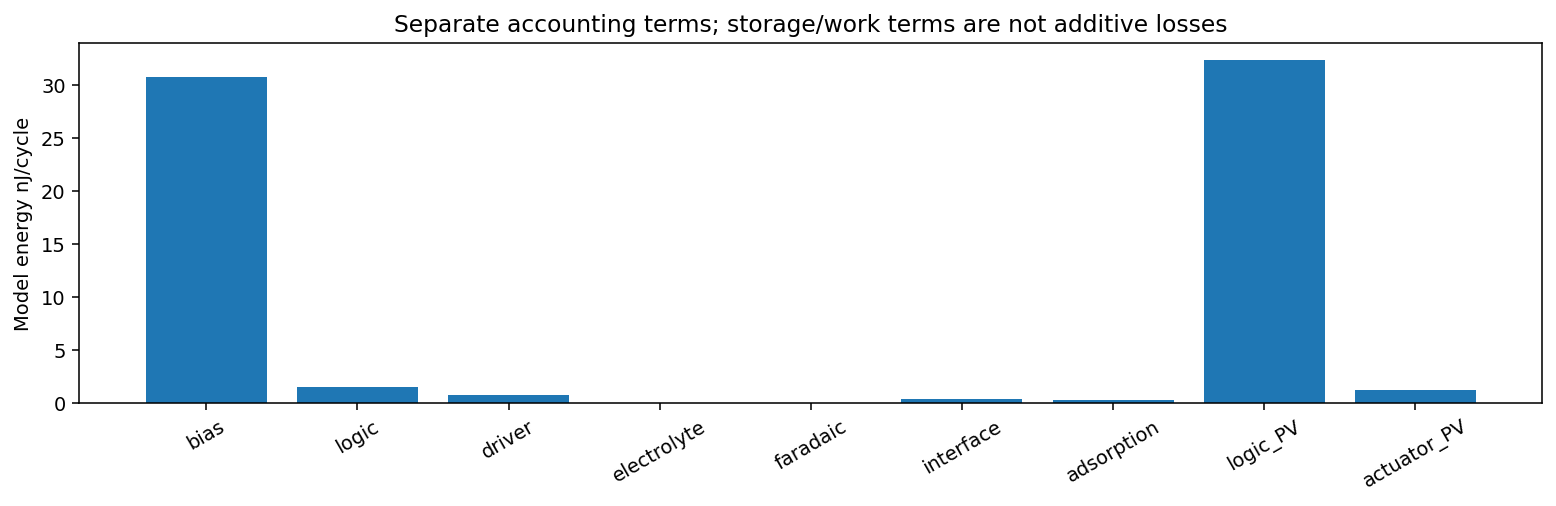

Parameter (units in name),Value
logic_series_cells,4
logic_cell_area_um2,1080
actuator_cell_area_um2,1080
logic_storage_F,5e-11
actuator_storage_each_F,2e-10
bias_current_A,5e-09
logic_leakage_A,2e-10
effective_switched_F,2e-14
clock_Hz_at_1v6,32768
divider,8192


This section reruns three model cases; the SPICE transients are rerun in Section 5.9, and no drift–diffusion or layout run is performed here.


In [8]:
parts=["bias","logic","driver","electrolyte","faradaic","interface","adsorption","logic_PV","actuator_PV"]
table(["Model energy term","Mean power nW","Energy nJ/cycle"],[(k,num(report["nominal"][k+"_mean_W"],1e9),num(report["nominal"][k+"_J_per_cycle"],1e9)) for k in parts])
fig,ax=plt.subplots(figsize=(11,3.5),layout="constrained")
ax.bar(parts,[report["nominal"][k+"_J_per_cycle"]*1e9 for k in parts]);ax.set(ylabel="Model energy nJ/cycle",title="Separate accounting terms; storage/work terms are not additive losses")
ax.tick_params(axis="x",rotation=30);showfig(fig)
table(["Parameter (units in name)","Value"],report["parameters"].items())
details("Cell allocation, model boundaries, exact input hashes and execution settings",{k:report[k] for k in ["design","model_limits","provenance","execution"]})
details("Archived model development attempts: three calculations before report serialization fix + three accepted",read("tcad_demo/execution_history.json"))
print("This section reruns three model cases; the SPICE transients are rerun in Section 5.9, and no drift–diffusion or layout run is performed here.")


### 5.5 Transistor Clock and Extracted-Layout Comparisons

All cases below reuse archived full-transient audits; Sections 5.9 and 5.10 rerun the transients, the layout flow and the extraction. Measured powers use the full adaptive data over exactly 2.4–4 ms, with interpolated boundaries, and thresholds follow instantaneous vdd/2. They use finite fitted-PV supplies at assumed cell scaling, unlike the drift–diffusion-powered system above. Nominal comparisons keep source, model, load and startup settings fixed; routing and placement changes are labelled. The 85 °C case changes the electronics temperature while holding the fitted PV at 26.85 °C.

The original RC layout was substantially slower than the schematic. Shorter stage-local routes and a compact placement improved this bench. A passing compact bench does not establish complete-controller feasibility or footprint acceptance. The earlier matched-review README keeps its historical preliminary status. These cases are not a full PVT or mismatch qualification.

In [9]:
clock_fine=read("clock_compact_convergence/metrics.json")
clock_hot=read("clock_compact_hot85/metrics.json")
cases=[("Schematic",25,26.85,compact["cases"]["schematic_25ns"]),
       ("Original extracted RC",25,26.85,compact["cases"]["extracted_25ns"]),
       ("Shorter stage-local routes",25,26.85,compact["cases"]["stage_local_25ns"]),
       ("Compact placement",25,26.85,compact["cases"]["compact_x_25ns"]),
       ("Compact fine",12.5,26.85,clock_fine["cases"]["compact_12p5ns"]),
       ("Compact hot, PV held 26.85°C",12.5,85,clock_hot["cases"]["electronics85_fixedPV26p85_12p5ns"])]
table(["Case","Max step ns","Electronics °C","Clock Hz","Analog nW","First DFF nW","Whole nW","Mean rail V","Rail min V","Rows","Stop s","Bench pass"],
      [(name,step,temp,num(v["edges"]["steady_clock_frequency_Hz"]),num(v["power_W"]["analog_clock"],1e9),num(v["power_W"]["first_ff_and_feedback"],1e9),num(v["power_W"]["whole_clock_and_first_ff"],1e9),num(v["rail_V"]["time_average"]),num(v["rail_V"]["minimum"]),v["rows"],v["actual_stop_s"],v["existing_bench_criterion_evaluation"]["passed"]) for name,step,temp,v in cases])
table(["25 ns → 12.5 ns observable","Coarse","Fine","Absolute relative difference","Threshold","Pass"],[(k,num(v["coarse_25ns"]),num(v["fine_12p5ns"]),num(v["absolute_relative_difference_to_fine"]),v["threshold"],v["passed"]) for k,v in clock_fine["comparisons"].items()])
table(["Hot sensitivity observable","Nominal","Hot","Hot / nominal"],[(k,num(v["nominal"]),num(v["hot85_fixed_PV"]),num(v["hot_over_nominal"])) for k,v in clock_hot["comparisons"].items()])
for title,record in [("Original matched pre/post-layout full-data audit",read("clock_layout_review/review_metrics.json")),("Shorter routes complete record",read("clock_local_routes/metrics.json")),("Compact clock timestep full-data audit",clock_fine),("Hot sensitivity full-data audit and fixed-PV temperature policy",clock_hot),("Schematic voltage/corner characterization used by the system lookup",read("clock_final/summary.json"))]: details(title,record)


Case,Max step ns,Electronics °C,Clock Hz,Analog nW,First DFF nW,Whole nW,Mean rail V,Rail min V,Rows,Stop s,Bench pass
Schematic,25,26.85,13054.2,42.6468,0.937543,43.5843,1.77497,1.67895,182756,0.004,True
Original extracted RC,25,26.85,2927.58,41.075,1.64139,42.7164,1.73908,1.36894,164309,0.004,False
Shorter stage-local routes,25,26.85,5253.23,43.0377,2.67776,45.7154,1.74196,1.47387,168547,0.004,True
Compact placement,25,26.85,5954.46,43.6705,2.58444,46.2549,1.74318,1.51654,169690,0.004,True
Compact fine,12.5,26.85,5954.9,43.6724,2.58338,46.2558,1.74322,1.51674,328249,0.004,True
"Compact hot, PV held 26.85°C",12.5,85,8467.25,55.5994,3.49188,59.0913,1.63316,1.44503,332247,0.004,True


25 ns → 12.5 ns observable,Coarse,Fine,Absolute relative difference,Threshold,Pass
clock_frequency_Hz,5954.46,5954.9,7.45215e-05,0.01,True
analog_clock_power_W,4.36705e-08,4.36724e-08,4.48987e-05,0.01,True
first_ff_and_feedback_power_W,2.58444e-09,2.58338e-09,0.000412135,0.01,True
whole_clock_and_first_ff_power_W,4.62549e-08,4.62558e-08,1.93734e-05,0.01,True


Hot sensitivity observable,Nominal,Hot,Hot / nominal
clock_frequency_Hz,5954.9,8467.25,1.4219
analog_clock_power_W,4.36724e-08,5.55994e-08,1.2731
first_ff_and_feedback_power_W,2.58338e-09,3.49188e-09,1.35167
whole_clock_and_first_ff_power_W,4.62558e-08,5.90913e-08,1.27749
rail_time_average_V,1.74322,1.63316,0.936863
rail_minimum_V,1.51674,1.44503,0.952719
rail_maximum_V,1.82072,1.73647,0.953725


### 5.6 Physical Gates and Standalone Transistor Drivers

The physical gates below concern the compact clock macro only. DRC/LVS and negative controls check the specific extracted connectivity; the paint bounding box is not a footprint signoff. No complete-controller layout is claimed.

The standalone MOS-driver tests use finite actuator PV and reduced electrode interfaces, but ideal logic, phase and ready sources. Their passing preliminary excursion and error limits do not establish driver behavior inside the nonlinear coupled startup. The coupled system uses finite-resistance behavioral drivers instead.

Clock-macro physical gate / inventory,Recorded value
placement_drc,DRC_ERRORS 0
native_drc_pass,True
native_lvs_pass,True
negative_control_rejected,True
roundtrip_drc_pass,True
roundtrip_lvs_pass,True
rc_resistors,851
rc_capacitors,376
inventory,"{'FET': 29, 'MIM': 7, 'total': 36}"


Corner,Temp °C,Light W/m²,Max step s,Settled error mV,Clamp error mV,PV nW,Logic nW,Pass
tt,26.85,1000,5e-05,0.75214,1.7273,2.39462,0.00587344,True
ss,26.85,1000,5e-05,0.96228,3.61041,2.39384,-0.00168409,True
ff,26.85,1000,5e-05,0.60007,0.933919,2.4001,0.00585908,True
sf,26.85,1000,5e-05,1.02908,1.11494,2.39948,0.00158256,True
fs,26.85,1000,5e-05,0.56837,1.69344,2.40859,-0.0099544,True
tt,26.85,1000,2.5e-05,0.75279,1.72815,2.39523,0.00413231,True
tt,26.85,1000,5e-05,0.75216,1.72722,2.39474,0.00804351,True
tt,85,1000,5e-05,0.68402,1.28823,2.41955,0.0162179,True
tt,26.85,500,5e-05,0.88914,2.07869,2.2682,0.00250122,True


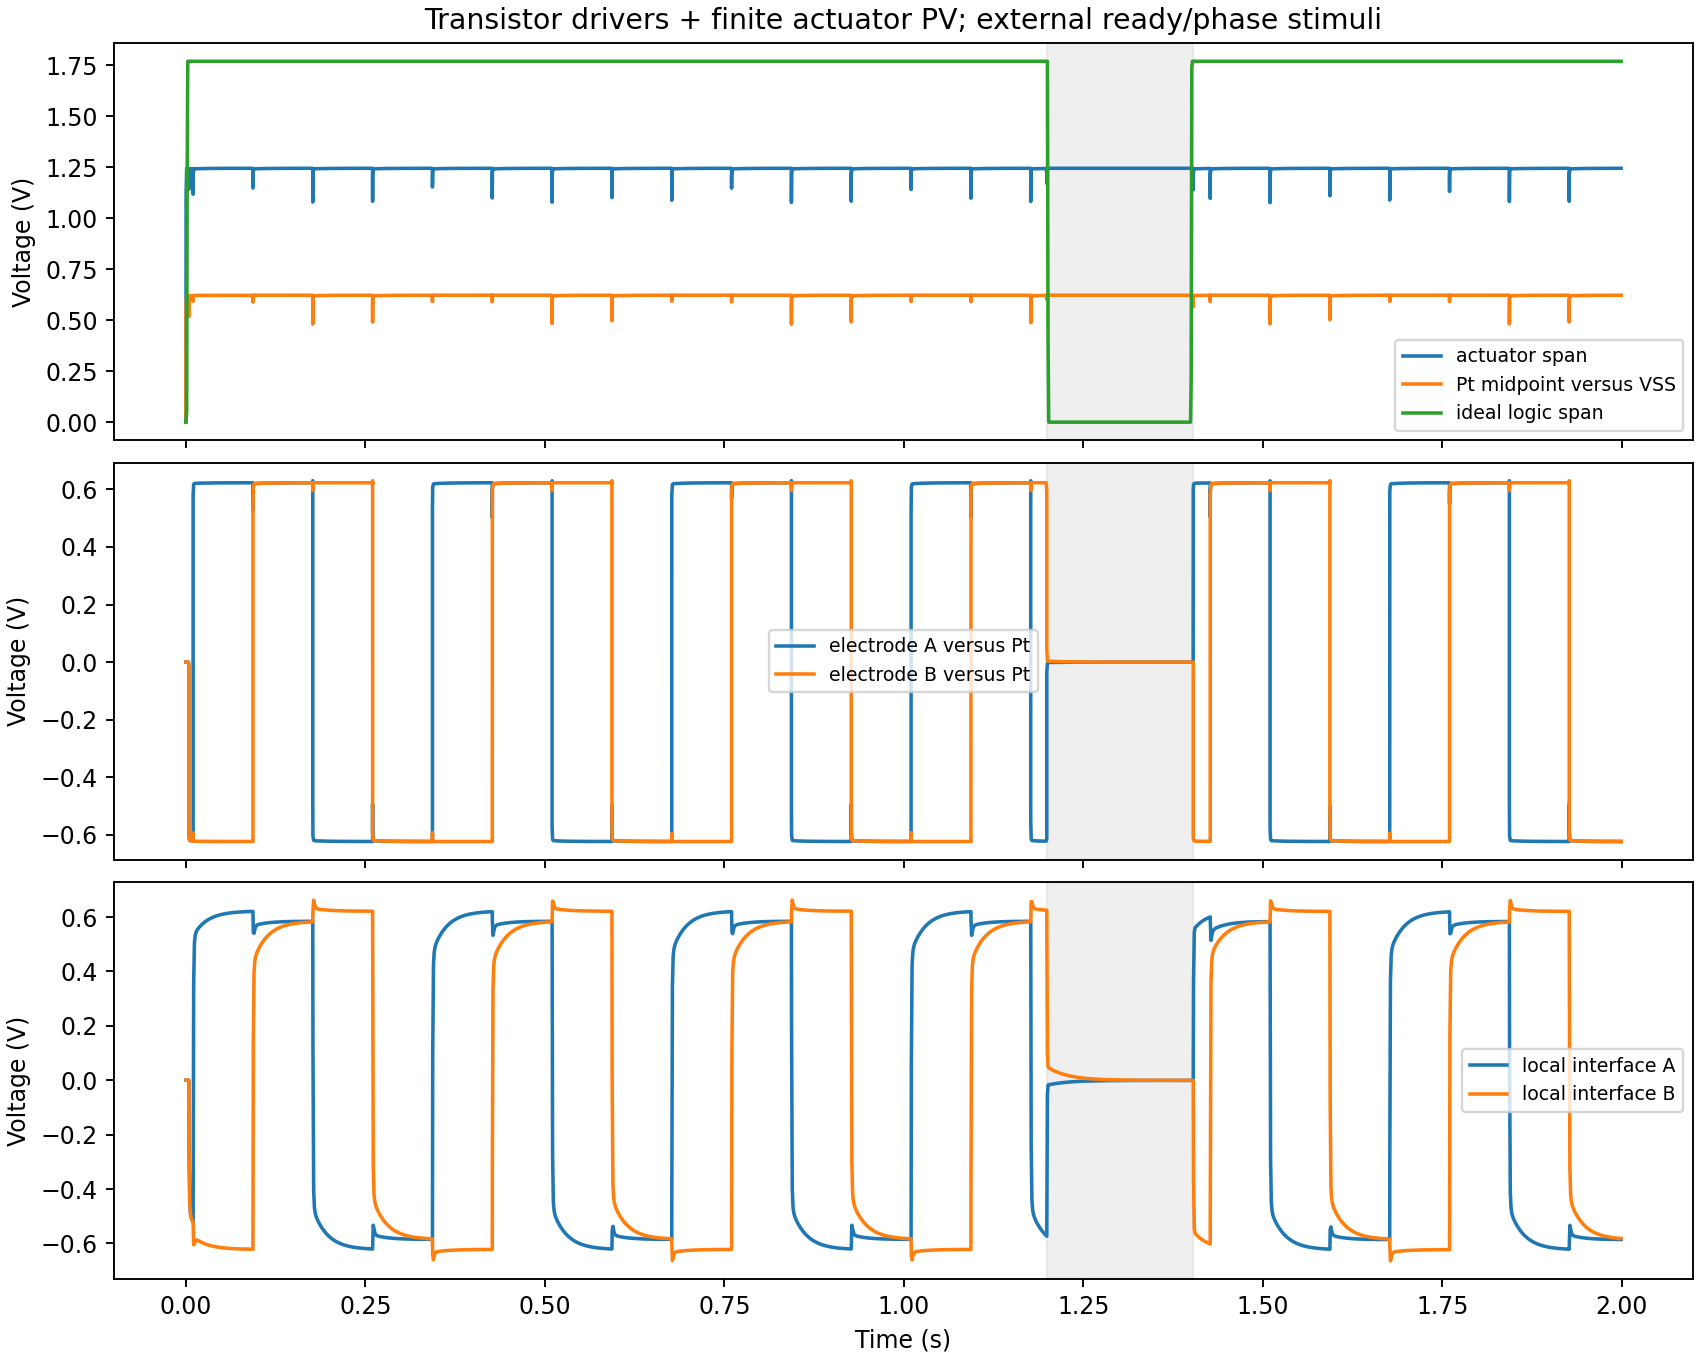

In [10]:
physical=compact["physical_gates"]
table(["Clock-macro physical gate / inventory","Recorded value"],[(k,physical[k]) for k in ["placement_drc","native_drc_pass","native_lvs_pass","negative_control_rejected","roundtrip_drc_pass","roundtrip_lvs_pass","rc_resistors","rc_capacitors","inventory"]])
details("Complete native/roundtrip compact physical report",read("clock_compact_placement/physical/report.json"))
drivers=read("electrical_v2/summary.json")
rows=list(drivers["drivers"])+[drivers[k] for k in ["driver_timestep_half","driver_slow_inputs","driver_hot","driver_half_light"]]
table(["Corner","Temp °C","Light W/m²","Max step s","Settled error mV","Clamp error mV","PV nW","Logic nW","Pass"],[(v["corner"],v["temperature_C"],v["irradiance_W_m2"],v["timestep_s"],num(v["settled_output_error_V"],1e3),num(v["reset_clamp_error_after_20ms_V"],1e3),num(v["actuator_PV_mean_W"],1e9),num(v["driver_logic_supply_mean_W"],1e9),v["passed"]) for v in rows])
picture(ARCHIVE/"electrical_v2/drivers.png",1000)
details("Complete standalone-driver and rejected-brownout summary",drivers)


### 5.7 Native Integration Failures and Diagnostic Boundaries

This chronology keeps the failed and limited evidence. A passing small-signal, linear, held-reset or isolated DC/AC diagnostic is not released nonlinear actuation, and no sequence of these results closes the original native startup failure or identifies a simulator defect as its root cause. The complete status and acceptance records are expandable below. Raw local transient paths and hashes can appear as historical references, but the raw transients are not bundled.

The final row is the mixed-abstraction demonstration above. It succeeds under its behavioral substitutions; the fully transistor-coupled controller remains unresolved.

In [11]:
history=[("Initial TCAD controller","tcad_controller"),("Held-reset logic isolation","tcad_logic_isolation"),("Held-input actuator add-back","tcad_actuator_startup"),("Passive held-input network","tcad_passive_clamps"),("Charge adsorption reformulation","tcad_charge_adsorption"),("Passive small-signal adsorption","tcad_passive_adsorption"),("Stable nonlinear formulation","tcad_stable_adsorption"),("Linear behavioral-source control","tcad_linear_bads"),("Isolated native DC/AC source-law audit","tcad_adsorption_source_audit"),("Reduced actuator-feedback replay","tcad_actuator_feedback_replay"),("Saved feedback-control outcomes","tcad_feedback_fix")]
rows=[]
for label,folder in history:
    status=read(folder+"/status.json"); metric=read(folder+"/metrics.json")
    if folder=="tcad_controller": metric=metric["nominal_25ns"]
    rows.append((label,status.get("status"),metric.get("complete",metric.get("passed","separate outcomes")),metric.get("actual_stop_s","—"),metric.get("requested_stop_s","—")))
    details(label+": full status and numerical record",{"status":status,"metrics":read(folder+"/metrics.json")})
rows.append(("Fresh mixed-abstraction model","15 gates pass; behavioral substitutions stated",report["all_gates_pass"],6.0,6.0))
table(["Investigation","Recorded status","Completion / local check","Actual stop s","Requested stop s"],rows)


Investigation,Recorded status,Completion / local check,Actual stop s,Requested stop s
Initial TCAD controller,BLOCKED: nominal functional/completion gate failed; no rescue or fine run,False,8.75048974811126e-05,0.008
Held-reset logic isolation,Complete held-reset logic isolation,True,0.00025,0.00025
Held-input actuator add-back,Incomplete held-input actuator add-back,False,8.153426298620898e-05,0.00025
Passive held-input network,Incomplete passive held-input startup,False,0.00015154093709365786,0.00025
Charge adsorption reformulation,Incomplete nonlinear series adsorption held-input startup,False,8.153455118471049e-05,0.00025
Passive small-signal adsorption,Complete passive small-signal adsorption diagnostic,True,0.00025,0.00025
Stable nonlinear formulation,Incomplete stable nonlinear held-input startup,False,0.00015154115448994557,0.00025
Linear behavioral-source control,Complete linear-B held-input startup,True,0.00025,0.00025
Isolated native DC/AC source-law audit,Isolated native DC/AC audit agrees,True,—,—
Reduced actuator-feedback replay,Incomplete reduced actuator-feedback replay,False,4.41052575471301e-05,—


### 5.8 Full Records and Reproduction

The saved outputs carry every summary metric, model parameter, input hash, gate, nominal/fine/dark completion record, archived clock comparison, compact geometry and physical report, standalone driver summary and selected integration-failure record. Expand any “Complete…” disclosure above to read the JSON without rerunning. The full reduced-system time series is also available as compressed CSV.

The compact clock is separate from the schematic lookup used by the coupled system. PV calibration, cell isolation, capacitor area, protection and level shifting, full-controller layout, PVT and mismatch, force and contact mechanics, and locomotion remain open. A half-timestep comparison at one condition is not general convergence, and the hot clock sensitivity does not resolve the earlier hot coupled-controller failure.

Python packages are pinned, and Section 3 installs the missing ones. Historical figure-derived and supplied measurement CSVs are excluded from this export, and paper-derived summaries do not transfer rights in the source data; see [attribution](ATTRIBUTION.md). Apart from the live OpenTCAD solve in Section 4 and the clock transients, layout and extraction rerun in Sections 5.9 and 5.10, no paper download, measurement fitting, drift–diffusion or SPICE simulation, or physical extraction is run here.

`submission.json` identifies the packaged content. The executor verifies source and reference hashes before and after execution and records the environment. Outputs from a run go under `local_runs/`.

In [12]:
for path in [OUTPUT/"summary.json",OUTPUT/"waveforms.csv.gz",ARCHIVE/"pv.json",ARCHIVE/"clock_compact_placement/metrics.json",ARCHIVE/"clock_compact_convergence/metrics.json",ARCHIVE/"clock_compact_hot85/metrics.json",ARCHIVE/"pv_calibration_feasibility/metrics.json",ARCHIVE/"electrical_v2/summary.json"]:
    link = os.path.relpath(path).replace(os.sep, "/")
    display(HTML('<a href="'+html.escape(link)+'" target="_blank">'+html.escape(link)+'</a>'))
print("All 15 fresh model gates passed; all source/reference records above are archived evidence unless labelled fresh.")

All 15 fresh model gates passed; all source/reference records above are archived evidence unless labelled fresh.


### 5.9 Rerunning the Clock Transients with Open Tools

The clock results in Section 5.5 come from ngspice runs I made earlier. This section reruns the six transients behind them (four layouts at 25 ns, the compact layout at 12.5 ns, and the compact layout with the electronics at 85 °C) from the archived SPICE decks and compares the new numbers with the archived ones. The decks are the extracted netlists saved with the evidence; only the simulator and the SKY130A models are new.

On Linux x86-64 the next cell installs ngspice, Magic and Netgen from conda with micromamba, and the SKY130A PDK at the version of the archived runs (open_pdks 1.0.535, commit a492ff7) from the GitHub release assets. Elsewhere it uses tools and a PDK that it finds on your machine (`PDK_ROOT`), or skips Sections 5.9 and 5.10. Set `RERUN_EDA = False` to skip them. The simulator and Magic versions differ from the archived runs (ngspice 41 against 44.2, Magic 8.3.486 against 8.3.546, the nearest conda version), so agreement is a result, not a given. The cell also compares the hashes of the PDK files with those recorded for the archived run.

In [13]:
RERUN_EDA = True      # False skips Sections 5.9 and 5.10 and keeps the archived clock results only

import platform
EDA_DIR = Path.cwd().resolve() / "eda_tools"
EDA_ENV = EDA_DIR / "env"
PDK_DIR = EDA_DIR / "pdk"
MICROMAMBA = "https://conda.anaconda.org/conda-forge/linux-64/micromamba-2.10.0-0.tar.bz2"
PDK_COMMIT = "a492ff787163f93ce9ebc382b23c58c0de33afa3"      # open_pdks 1.0.535, the version of the archived runs
PDK_RELEASE = f"https://github.com/fossi-foundation/ciel-releases/releases/download/sky130-{PDK_COMMIT}/"
LIBRARY = "sky130A/libs.tech/ngspice/sky130.lib.spice"

def find_tools():
    search = os.pathsep.join([str(EDA_ENV / "bin"), os.environ.get("PATH", "")])
    tools = {name: shutil.which(name, path=search) for name in ("ngspice", "magic", "netgen")}
    roots = [os.environ.get("PDK_ROOT"), "/usr/local/share/pdk", "/usr/share/pdk", str(PDK_DIR)]
    root = next((Path(r) for r in roots if r and (Path(r) / LIBRARY).is_file()), None)
    return tools, root

def install_tools():
    EDA_DIR.mkdir(exist_ok=True)
    mamba = EDA_DIR / "micromamba"
    if not mamba.exists():
        with tempfile.TemporaryFile() as archive:
            with urllib.request.urlopen(MICROMAMBA, timeout=120) as response:
                shutil.copyfileobj(response, archive)
            archive.seek(0)
            with tarfile.open(fileobj=archive, mode="r:bz2") as tar:
                member = tar.getmember("bin/micromamba")
                member.name = "micromamba"
                tar.extract(member, EDA_DIR, filter="data")
        mamba.chmod(0o755)
    if not EDA_ENV.exists():
        result = subprocess.run([str(mamba), "create", "-y", "-q", "-p", str(EDA_ENV), "--override-channels",
                                 "-c", "conda-forge", "-c", "litex-hub",
                                 "conda-forge::ngspice", "conda-forge::magic=8.3.486", "litex-hub::netgen"],
                                capture_output=True, text=True, env={**os.environ, "MAMBA_ROOT_PREFIX": str(EDA_DIR / "root")})
        if result.returncode:
            print(result.stderr[-1500:])
    if not (PDK_DIR / LIBRARY).is_file():
        if importlib.util.find_spec("zstandard") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "zstandard"], capture_output=True)
            importlib.invalidate_caches()
        import zstandard
        for name in ("common", "sky130_fd_pr"):
            with tempfile.TemporaryFile() as archive:
                with urllib.request.urlopen(PDK_RELEASE + name + ".tar.zst", timeout=300) as response:
                    shutil.copyfileobj(response, archive)
                archive.seek(0)
                with tarfile.open(fileobj=zstandard.ZstdDecompressor().stream_reader(archive), mode="r|") as tar:
                    for member in tar:
                        if member.name.startswith("sky130A/"):
                            tar.extract(member, PDK_DIR, filter="data")

tools, pdk_root = find_tools() if RERUN_EDA else ({}, None)
if RERUN_EDA and not (tools.get("ngspice") and pdk_root) and sys.platform.startswith("linux") and platform.machine() in ("x86_64", "AMD64"):
    print("Installing ngspice, Magic, Netgen and the SKY130A PDK ...")
    started = time.time()
    install_tools()
    tools, pdk_root = find_tools()
    print(f"Install took {time.time() - started:.0f} s")
ngspice, magic, netgen = tools.get("ngspice"), tools.get("magic"), tools.get("netgen")
library = pdk_root / LIBRARY if pdk_root else None
tools_ready = bool(ngspice and library)
layout_tools_ready = bool(tools_ready and magic and netgen)
tool_versions = {}
if tools_ready:
    tool_versions["ngspice"] = re.search(r"ngspice-[\d.]+", subprocess.run([ngspice, "--version"], capture_output=True, text=True).stdout).group(0)
    if magic:
        tool_versions["magic"] = "magic " + subprocess.run([magic, "--version"], capture_output=True, text=True).stdout.strip()
    netgen_meta = sorted(EDA_ENV.glob("conda-meta/netgen-*.json"))
    if netgen:
        tool_versions["netgen"] = netgen_meta[0].name.rsplit(".json", 1)[0].replace("netgen-", "netgen ") if netgen_meta else "netgen (version not recorded)"
    tool_versions["pdk"] = (f"SKY130A open_pdks 1.0.535 (commit {PDK_COMMIT[:7]})" if pdk_root == PDK_DIR else "SKY130A found on this machine")
    expected = read("native_tools_m3.json")["pdk_files_sha256"]
    matches = {Path(name).name: hashlib.sha256((pdk_root / "sky130A" / name).read_bytes()).hexdigest() == digest
               for name, digest in expected.items() if (pdk_root / "sky130A" / name).is_file()}
    tool_versions["pdk_files_matching_archived_hashes"] = sorted(k for k, v in matches.items() if v)
    tool_versions["pdk_files_differing_from_archived_hashes"] = sorted(k for k, v in matches.items() if not v)
    print("Tools:", ", ".join(tool_versions[k] for k in ("ngspice", "magic", "netgen", "pdk") if k in tool_versions))
    print("PDK files matching the archived hashes:", ", ".join(tool_versions["pdk_files_matching_archived_hashes"]) or "none")
    print("PDK files that differ from the archived hashes:", ", ".join(tool_versions["pdk_files_differing_from_archived_hashes"]) or "none")
elif RERUN_EDA:
    print("No ngspice with the SKY130A PDK found, and none can be installed automatically here. "
          "Install the tools, set PDK_ROOT, and rerun this cell. The archived clock results above stay valid.")
else:
    print("Skipped: RERUN_EDA is False.")

Installing ngspice, Magic, Netgen and the SKY130A PDK ...


Install took 10 s
Tools: ngspice-41, magic 8.3.486, netgen 1.5.272_0_g178af5f-20240223_100318, SKY130A open_pdks 1.0.535 (commit a492ff7)
PDK files matching the archived hashes: sky130.lib.spice, sky130A_setup.tcl
PDK files that differ from the archived hashes: sky130A.magicrc, sky130A.tcl, sky130A.tech


In [14]:
rerun_summary = {}
if tools_ready:
    from concurrent.futures import ThreadPoolExecutor
    CASES = [("Schematic", "clock_layout_review/schematic_25ns", 25, compact["cases"]["schematic_25ns"]),
             ("Original extracted RC", "clock_layout_review/extracted_25ns", 25, compact["cases"]["extracted_25ns"]),
             ("Shorter stage-local routes", "clock_local_routes", 25, compact["cases"]["stage_local_25ns"]),
             ("Compact placement", "clock_compact_placement", 25, compact["cases"]["compact_x_25ns"]),
             ("Compact fine", "clock_compact_convergence", 12.5, clock_fine["cases"]["compact_12p5ns"]),
             ("Compact hot, PV held 26.85 °C", "clock_compact_hot85", 12.5, clock_hot["cases"]["electronics85_fixedPV26p85_12p5ns"])]

    def clock_metrics(path):
        data = np.loadtxt(path, skiprows=1)
        t, vdd, clk, bn, bp, analog, digital, q = data.T
        steady = t > 0.0024
        y = clk - vdd / 2
        index = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
        rises = t[index] - y[index] * np.diff(t)[index] / np.diff(y)[index]
        rises = rises[rises > t[steady][0]]
        power = float(np.trapezoid((vdd * (analog + digital))[steady], t[steady]) / np.ptp(t[steady]))
        return {"rows": len(data), "stop_s": float(t[-1]), "finite": bool(np.isfinite(data).all()),
                "steady_clock_rises": len(rises), "frequency_Hz": float(1 / np.mean(np.diff(rises))),
                "whole_power_W": power, "rail_min_V": float(vdd[steady].min())}

    def simulate(case):
        label, source, step_ns, archived = case
        folder = OUTPUT / "clock_rerun" / source.replace("/", "_")
        folder.mkdir(parents=True)
        for name in ("clock.spice", "receiver_cells.spice"):
            text = (ARCHIVE / source / name).read_text()
            text = re.sub(r'(?m)^(\.lib )"[^"]*sky130\.lib\.spice"', lambda m: m.group(1) + '"' + str(library) + '"', text)
            (folder / name).write_text(text)
        (folder / ".spiceinit").write_text("set ngbehavior=hsa\nset num_threads=1\n")
        started = time.time()
        process = subprocess.run([ngspice, "-b", "clock.spice"], cwd=folder, capture_output=True, text=True)
        wall = time.time() - started
        (folder / "ngspice.log").write_text(process.stdout + process.stderr)
        metrics = clock_metrics(folder / "clock.dat") if process.returncode == 0 and (folder / "clock.dat").is_file() else None
        if (folder / "clock.dat").is_file():
            (folder / "clock.dat").unlink()      # tens of MB each; the metrics are kept
        return label, step_ns, archived, metrics, wall

    print("Running", len(CASES), "ngspice transients, up to", min(3, os.cpu_count() or 1), "at a time ...")
    with ThreadPoolExecutor(max_workers=min(3, os.cpu_count() or 1)) as pool:
        results = list(pool.map(simulate, CASES))

    def change(new, old):
        return f"{(new / old - 1) * 100:+.4f} %"
    rows, record = [], {}
    for label, step_ns, archived, metrics, wall in results:
        old_f, old_p = archived["edges"]["steady_clock_frequency_Hz"], archived["power_W"]["whole_clock_and_first_ff"]
        if metrics is None:
            rows.append((label, step_ns, "failed", num(old_f), "—", "failed", num(old_p, 1e9), "—", f"{wall:.0f}"))
            continue
        complete = metrics["finite"] and abs(metrics["stop_s"] - 0.004) < 1e-9
        rows.append((label, step_ns, num(metrics["frequency_Hz"]), num(old_f), change(metrics["frequency_Hz"], old_f),
                     num(metrics["whole_power_W"], 1e9), num(old_p, 1e9), change(metrics["whole_power_W"], old_p), f"{wall:.0f}" + ("" if complete else " (incomplete)")))
        record[label] = {**metrics, "wall_s": round(wall), "archived_frequency_Hz": old_f, "archived_whole_power_W": old_p,
                         "archived_rows": archived["rows"], "max_step_ns": step_ns}
    table(["Case", "Max step ns", "Clock Hz, rerun", "Clock Hz, archived", "Difference", "Whole nW, rerun", "Whole nW, archived", "Difference", "Wall s"], rows)
    if "Schematic" in record and "Compact placement" in record:
        ratio = record["Compact placement"]["frequency_Hz"] / record["Schematic"]["frequency_Hz"]
        archived_ratio = record["Compact placement"]["archived_frequency_Hz"] / record["Schematic"]["archived_frequency_Hz"]
        print(f"Extracted compact layout runs at {ratio:.1%} of the schematic clock frequency (archived runs: {archived_ratio:.1%}).")
        rerun_summary = {"schematic_Hz": record["Schematic"]["frequency_Hz"], "compact_Hz": record["Compact placement"]["frequency_Hz"],
                         "compact_power_W": record["Compact placement"]["whole_power_W"]}
    details("Complete rerun record, with tool versions", {"tools": tool_versions, "cases": record})

Running 6 ngspice transients, up to 2 at a time ...


Case,Max step ns,"Clock Hz, rerun","Clock Hz, archived",Difference,"Whole nW, rerun","Whole nW, archived",Difference,Wall s
Schematic,25,13054.2,13054.2,-0.0000 %,43.5845,43.5843,+0.0003 %,44
Original extracted RC,25,2927.57,2927.58,-0.0003 %,42.7141,42.7164,-0.0054 %,66
Shorter stage-local routes,25,5253.2,5253.23,-0.0006 %,45.7157,45.7154,+0.0005 %,69
Compact placement,25,5954.44,5954.46,-0.0002 %,46.255,46.2549,+0.0002 %,70
Compact fine,12.5,5954.91,5954.9,+0.0002 %,46.2559,46.2558,+0.0003 %,117
"Compact hot, PV held 26.85 °C",12.5,8467.28,8467.25,+0.0003 %,59.0915,59.0913,+0.0004 %,117


Extracted compact layout runs at 45.6% of the schematic clock frequency (archived runs: 45.6%).


### 5.10 Rerunning the Layout, DRC, LVS and Parasitic Extraction

The compact clock layout of Section 5.1 is generated by `examples/microrobot/clock_layout.py`: Magic builds the transistors and capacitors from the PDK cell generators, places and routes them, runs DRC, extracts a netlist and checks it against the source with Netgen LVS, repeats DRC and LVS on a GDS round trip, checks that a deliberately wrong net is rejected, and extracts the parasitic resistors and capacitors. The next cell reruns that whole flow with the tools installed above and compares each result with the archived report.

It then replaces the extracted parasitic network inside the archived 25 ns deck by the freshly extracted one and simulates it again. The layout does not depend on the Magic version, but the extraction does: it changes the number of extracted parasitics and the order of the subcircuit ports, which the cell accounts for. This step shows how much the clock result moves with the extractor.

In [15]:
physical_summary = {}
if layout_tools_ready:
    from examples.microrobot import clock_layout
    os.environ["PATH"] = os.pathsep.join([str(Path(magic).parent), os.environ.get("PATH", "")])
    os.environ.update(PDK_ROOT=str(pdk_root), NETGEN=netgen)
    LAYOUT = OUTPUT / "clock_layout_rerun"
    started = time.time()
    fresh = clock_layout.run(LAYOUT, routing="stage_local", placement="compact_x")
    layout_wall = time.time() - started
    archived_report = read("clock_compact_placement/physical/report.json")

    def paint(path):
        return "\n".join(line for line in path.read_text().splitlines() if not line.startswith("timestamp"))
    def drc_errors(text):
        found = re.match(r"DRC_ERRORS (\d+)", text or "")
        return int(found.group(1)) if found else None
    identical = paint(LAYOUT / "microrobot_clock.mag") == paint(ARCHIVE / "clock_compact_placement/physical/microrobot_clock.mag")
    gate_rows = [("Magic paint identical to the archived layout (timestamps ignored)", identical, True),
                 ("Placement DRC errors", drc_errors(fresh.get("placement_drc")), drc_errors(archived_report.get("placement_drc"))),
                 ("Native DRC errors", drc_errors(fresh.get("native_drc")), drc_errors(archived_report.get("native_drc"))),
                 ("Native LVS matches the source", fresh.get("native_lvs_pass"), archived_report.get("native_lvs_pass")),
                 ("Wrong-net negative control rejected", fresh.get("negative_control_rejected"), archived_report.get("negative_control_rejected")),
                 ("GDS round-trip DRC passes", fresh.get("roundtrip_drc_pass"), archived_report.get("roundtrip_drc_pass")),
                 ("GDS round-trip LVS matches", fresh.get("roundtrip_lvs_pass"), archived_report.get("roundtrip_lvs_pass")),
                 ("Extracted parasitic resistors", fresh.get("rc_resistors"), archived_report.get("rc_resistors")),
                 ("Extracted parasitic capacitors", fresh.get("rc_capacitors"), archived_report.get("rc_capacitors"))]
    print(f"Layout flow finished in {layout_wall:.0f} s: {fresh.get('status')}")
    table(["Physical gate", "Rerun", "Archived"], gate_rows)

    # Simulate the archived deck again, with the freshly extracted RC network in place of the archived one.
    def block(lines):
        start = next(i for i, line in enumerate(lines) if line.lower().startswith(".subckt microrobot_clock"))
        return start, next(i for i in range(start, len(lines)) if lines[i].lower().startswith(".ends"))
    deck = (ARCHIVE / "clock_compact_placement/clock.spice").read_text().splitlines()
    network = (LAYOUT / "clock_rc.spice").read_text().splitlines()
    (a, b), (c, d) = block(deck), block(network)
    text = "\n".join(deck[:a] + network[c:d + 1] + deck[b + 1:]) + "\n"
    # Magic versions list the subcircuit ports in different orders, so rebuild the instance line from the new header.
    ports = re.match(r"(?i)\.subckt microrobot_clock (.*)", network[c]).group(1).split()
    nets = {"clk": "clk", "vdd": "vdd", "vss": "0", "bias_n": "bn", "bias_p": "bp"}
    instance = "Xclock clk vdd 0 bn bp microrobot_clock"
    assert text.count(instance) == 1
    text = text.replace(instance, "Xclock " + " ".join(nets[p] for p in ports) + " microrobot_clock")
    text = re.sub(r'(?m)^(\.lib )"[^"]*sky130\.lib\.spice"', lambda m: m.group(1) + '"' + str(library) + '"', text)
    folder = LAYOUT / "extracted_25ns"
    folder.mkdir()
    (folder / "clock.spice").write_text(text)
    shutil.copy2(ARCHIVE / "clock_compact_placement/receiver_cells.spice", folder / "receiver_cells.spice")
    (folder / ".spiceinit").write_text("set ngbehavior=hsa\nset num_threads=1\n")
    started = time.time()
    process = subprocess.run([ngspice, "-b", "clock.spice"], cwd=folder, capture_output=True, text=True)
    (folder / "ngspice.log").write_text(process.stdout + process.stderr)
    if process.returncode == 0 and (folder / "clock.dat").is_file():
        metrics = clock_metrics(folder / "clock.dat")
        (folder / "clock.dat").unlink()
        old = compact["cases"]["compact_x_25ns"]
        old_f, old_p = old["edges"]["steady_clock_frequency_Hz"], old["power_W"]["whole_clock_and_first_ff"]
        table(["Compact layout, 25 ns", "Fresh extraction", "Archived extraction", "Difference"],
              [("Clock frequency (Hz)", num(metrics["frequency_Hz"]), num(old_f), change(metrics["frequency_Hz"], old_f)),
               ("Clock + first flip-flop power (nW)", num(metrics["whole_power_W"], 1e9), num(old_p, 1e9), change(metrics["whole_power_W"], old_p)),
               ("Minimum rail voltage (V)", num(metrics["rail_min_V"]), num(old["rail_V"]["minimum"]), change(metrics["rail_min_V"], old["rail_V"]["minimum"]))])
        physical_summary = {"frequency_Hz": metrics["frequency_Hz"], "archived_Hz": old_f, "resistors": fresh.get("rc_resistors"),
                            "capacitors": fresh.get("rc_capacitors"), "wall_s": round(time.time() - started)}
        if "Schematic" in record:
            fraction = metrics["frequency_Hz"] / record["Schematic"]["frequency_Hz"]
            archived_fraction = old_f / record["Schematic"]["archived_frequency_Hz"]
            physical_summary.update(fraction=fraction, archived_fraction=archived_fraction)
            print(f"With the freshly extracted network the compact layout runs at {fraction:.1%} of the schematic clock frequency; the archived extraction gives {archived_fraction:.1%}.")
    else:
        print("The transient with the fresh extraction did not complete; see the log in", folder.relative_to(ROOT))
    details("Complete layout rerun report and tool versions", {"tools": tool_versions, "report": {k: v for k, v in fresh.items() if k != "scope"}})
else:
    print("Skipped: needs ngspice, Magic, Netgen and the SKY130A PDK (RERUN_EDA and tool installation above).")

Layout flow finished in 2 s: Physical gates passed; extracted electrical validation pending


Physical gate,Rerun,Archived
Magic paint identical to the archived layout (timestamps ignored),True,True
Placement DRC errors,0,0
Native DRC errors,0,0
Native LVS matches the source,True,True
Wrong-net negative control rejected,True,True
GDS round-trip DRC passes,True,True
GDS round-trip LVS matches,True,True
Extracted parasitic resistors,773,851
Extracted parasitic capacitors,332,376


"Compact layout, 25 ns",Fresh extraction,Archived extraction,Difference
Clock frequency (Hz),5936.19,5954.46,-0.3067 %
Clock + first flip-flop power (nW),46.3467,46.2549,+0.1984 %
Minimum rail voltage (V),1.51396,1.51654,-0.1702 %


With the freshly extracted network the compact layout runs at 45.5% of the schematic clock frequency; the archived extraction gives 45.6%.


## 6. Results

The table below is assembled from the variables and archived records used in Sections 4 and 5. No number in it is typed by hand: each value is read from this notebook's own run or from the bundled evidence files. Rows are labelled fresh or archived.

In [16]:
def get(obj, *path, default=None):
    for key in path:
        try: obj = obj[key]
        except (KeyError, IndexError, TypeError): return default
    return obj

gates = get(compact, "physical_gates", default={})
freq = get(compact, "comparison", "frequency_Hz", default={})
bbox = get(compact, "area", "compact_x", "bounding_box_area_um2")
power_fine = get(clock_fine, "comparisons", "whole_clock_and_first_ff_power_W", "fine_12p5ns")
nominal = get(report, "nominal", default={})

P1 = "fresh · Section 4" if live_error is None else "archived · Section 4"
rows = [
    [P1, "Short-circuit current of the illuminated cell (nA)", num(isc, 1e9)],
    [P1, "Open-circuit voltage (V)", num(voc_tcad)],
    [P1, "Maximum power, TCAD vs compact model (nW)", f"{num(pmax_tcad, 1e9)} vs {num(pmax_m, 1e9)}"],
    [P1, "Collected fraction of absorbed photons (must be ≤ 1)", f"{collection:.3f}"],
    ["archived · clock macro", "Native DRC / LVS pass (compact clock macro)", f"{get(gates, 'native_drc_pass')} / {get(gates, 'native_lvs_pass')}"],
    ["archived · clock macro", "Clock frequency: schematic vs extracted compact layout (Hz)", f"{num(freq.get('schematic_25ns'))} vs {num(freq.get('compact_x_25ns'))}"],
    ["archived · clock macro", "Clock + first flip-flop power, extracted compact layout (nW)", num(power_fine, 1e9)],
    ["archived · clock macro", "Paint bounding box of the compact macro (µm²)", num(bbox)],
    ["fresh · Section 5 system", "Mean gait frequency (Hz)", num(get(nominal, "mean_gait_Hz"))],
    ["fresh · Section 5 system", "Measured phase lag of output B (cycles)", num(get(nominal, "measured_phase_B_lag_cycles"))],
    ["fresh · Section 5 system", "Predicted bending, peak to peak (rad)", num(get(nominal, "bending_peak_to_peak_rad"))],
    ["fresh · Section 5 system", "All model gates passed", str(get(report, "all_gates_pass"))],
]
if rerun_summary:
    rows[8:8] = [
        ["fresh · Section 5.9", "Clock frequency rerun: schematic vs extracted compact layout (Hz)", f"{num(rerun_summary['schematic_Hz'])} vs {num(rerun_summary['compact_Hz'])}"],
        ["fresh · Section 5.9", "Clock + first flip-flop power, extracted compact layout, rerun (nW)", num(rerun_summary["compact_power_W"], 1e9)],
    ]
if physical_summary:
    rows[8:8] = [
        ["fresh · Section 5.10", "Layout rerun: native DRC errors / LVS match / GDS round-trip DRC and LVS pass", f"{get(fresh, 'native_drc', default='')[:12].strip()} / {get(fresh, 'native_lvs_pass')} / {get(fresh, 'roundtrip_drc_pass')} and {get(fresh, 'roundtrip_lvs_pass')}"],
        ["fresh · Section 5.10", "Extracted resistors / capacitors, rerun vs archived", f"{physical_summary['resistors']} / {physical_summary['capacitors']} vs {get(archived_report, 'rc_resistors')} / {get(archived_report, 'rc_capacitors')}"],
        ["fresh · Section 5.10", "Clock frequency with freshly extracted parasitics vs archived extraction (Hz)", f"{num(physical_summary['frequency_Hz'])} vs {num(physical_summary['archived_Hz'])}"],
    ]
table(["Evidence", "Quantity", "Value"], rows)

Evidence,Quantity,Value
fresh · Section 4,Short-circuit current of the illuminated cell (nA),2.74161
fresh · Section 4,Open-circuit voltage (V),0.461028
fresh · Section 4,"Maximum power, TCAD vs compact model (nW)",0.974835 vs 0.98815
fresh · Section 4,Collected fraction of absorbed photons (must be ≤ 1),0.620
archived · clock macro,Native DRC / LVS pass (compact clock macro),True / True
archived · clock macro,Clock frequency: schematic vs extracted compact layout (Hz),13054.2 vs 5954.46
archived · clock macro,"Clock + first flip-flop power, extracted compact layout (nW)",46.2558
archived · clock macro,Paint bounding box of the compact macro (µm²),39243.7
fresh · Section 5.10,Layout rerun: native DRC errors / LVS match / GDS round-trip DRC and LVS pass,DRC_ERRORS 0 / True / True and True
fresh · Section 5.10,"Extracted resistors / capacitors, rerun vs archived",773 / 332 vs 851 / 376


## 7. Discussion

### 7.1 What the Results Support

The OpenTCAD extension behaves physically: the collected current stays below the absorbed-photon bound, the dark cell delivers essentially nothing at zero bias, and a three-parameter compact model reproduces the TCAD short-circuit current, open-circuit voltage and maximum power closely enough to drive a circuit simulation. The compact clock macro passes native DRC and LVS, and its extracted layout is slower than the schematic, as parasitics would suggest; a more compact placement recovered part of that loss.

### 7.2 What They Do Not Support

- The TCAD cell is conceptual. Its responsivity (about 0.14 A/W) and open-circuit voltage (about 0.46 V) are below the approximate published values of about 0.3 A/W and 0.6 V per cell, and I do not claim to reproduce the published device.
- The full transistor-coupled controller never started reliably. The Section 5 system succeeds only under behavioral substitutions for the divider, reset and drivers, and it should not be read as closing that failure.
- The size of the extracted-layout penalty depends on the parasitic extractor. In the saved run, extracting with Magic 8.3.678 instead of the 8.3.546 used for the archived runs gives fewer parasitic elements and a clock frequency about 38 % higher (Section 5.10). The extracted layout is slower than the schematic in both cases, but the ratio is not a fixed property of the layout.
- Mechanics are assumed. The model predicts a bend angle, not force, contact or walking.
- Live values in Section 4 can differ in the last digits across Gmsh and DEVSIM builds because the mesh is generated at run time.

I report the failed and limited experiments (Section 5.7) because they show which diagnostics were tried and which boundaries they do and do not establish.

## 8. Conclusion and Possible Future Improvements

### 8.1 Conclusion

I extended OpenTCAD with optical generation, explicit current scaling, a SPICE-exportable photovoltaic compact model and a fix to the core solver, and ran the path from a structure definition to a SPICE macromodel live in a notebook, with a physical bound and a negative control. I then used the model in a microrobot-controller case study with a verified clock-macro layout. The case study falls short in the places listed in Section 7.2. The notebook can serve as a template for bringing device physics into open circuit-design flows, and as a starting point for anyone who wants to extend OpenTCAD.

### 8.2 To Do / Possible Future Improvements

- Calibrate the PV structure against measured devices, including surface recombination and a spectral optical model in OpenTCAD.
- Resolve the full transistor-coupled controller startup: brownout/power-on reset, level shifting and input protection.
- Complete the controller layout with PVT corners and mismatch analysis, and close the footprint.
- Add the process-simulation half (topography, implant, anneal) to the notebook's pinned environment and extend it with concentration-dependent diffusion and calibration against SKY130 and IHP data.
- Test and package the notebook for Google Colab.
- Add force, contact and friction mechanics before making any claim about locomotion.

## 9. References

[1] M. F. Reynolds et al., “Microscopic robots with onboard digital control,” *Science Robotics*, vol. 7, no. 70, eabq2296, 2022. https://doi.org/10.1126/scirobotics.abq2296

[2] M. Z. Miskin et al., “Electronically integrated, mass-manufactured, microscopic robots,” *Nature*, vol. 584, pp. 557–561, 2020. https://doi.org/10.1038/s41586-020-2626-9

[3] M. M. Lassiter et al., “Microscopic robots that sense, think, act, and compute,” *Science Robotics*, vol. 10, no. 109, 2025. https://doi.org/10.1126/scirobotics.adu8009

[4] L. C. Hanson et al., “Electrokinetic propulsion for electronically integrated microscopic robots,” *Proc. Natl. Acad. Sci. U.S.A.*, vol. 122, no. 29, 2025. https://doi.org/10.1073/pnas.2500526122

[5] L. Xu et al., “A 210×340×50 µm integrated CMOS system for micro-robots with energy harvesting, sensing, processing, communication, and actuation,” *IEEE International Solid-State Circuits Conference (ISSCC)*, 2022.

[6] DEVSIM semiconductor device simulator. https://devsim.org

[7] C. Geuzaine and J.-F. Remacle, “Gmsh: a 3-D finite element mesh generator with built-in pre- and post-processing facilities,” *Int. J. Numer. Methods Eng.*, vol. 79, no. 11, pp. 1309–1331, 2009.

[8] ViennaLS level-set library. https://viennatools.github.io/

[9] SkyWater SKY130 PDK and open_pdks. https://github.com/RTimothyEdwards/open_pdks

[10] ngspice circuit simulator, Magic VLSI layout tool and Netgen LVS tool. https://ngspice.sourceforge.io, https://opencircuitdesign.com/magic/, https://opencircuitdesign.com/netgen/

## 10. Acknowledgements

I thank the authors and maintainers of DEVSIM, Gmsh, ViennaLS, PyVista, NumPy and SciPy, ngspice, Magic, Netgen, open_pdks and the SkyWater SKY130 PDK, whose open-source work makes this notebook possible, and the authors of references [1]–[5], whose published results this case study builds on. Source attribution, the disclosed intellectual-property notice of [1] and data-licensing notes are in [ATTRIBUTION.md](ATTRIBUTION.md).